# V3_1 — 02B_Exhaustive_Circles_LOSO — KVO field-grounded final reference

**The original V3 training recipe, folds and hyperparameters are unchanged.** All V3_1 outputs and caches are kept under `Outputs/V3_1`. The new exhaustive v2 labels and the only newly audited, explicitly approved geometry repairs are used. Do not mix with V3 notebooks.


## 01 — Inputs and NB01 spatial folds


In [1]:
%pip -q install rasterio geopandas pyogrio shapely pandas matplotlib scikit-learn segmentation-models-pytorch
from pathlib import Path
import json, warnings, math, random, time
import numpy as np, pandas as pd, geopandas as gpd, rasterio, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box
from shapely.ops import unary_union
from shapely import make_valid
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import average_precision_score, roc_auc_score
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
                         Path('/content/drive/MyDrive/Musanga/Final')] if p.is_dir()),None)
assert ROOT is not None
OUT=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34';OUT.mkdir(parents=True,exist_ok=True)
REF=ROOT/'Outputs/V3_1/01_reference_data_no_MOS34'
A=json.loads((ROOT/'Outputs/V3_1/00_input_audit/00_input_manifest.json').read_text())
assert A.get('schema_version')=='v3_1_input_audit_kvo_final'
assert A.get('reference_version')=='KVO_field_final', 'Run updated V3_1 NB00 (KVO final) first'
assert A['exhaustive_annotations'].get('all_annotation_polygons_musanga') is True
assert int(A['exhaustive_annotations']['verified_exhaustive_circle_count'])==34
EXCLUDED_MOSAIC='Mos_3_4_transparent_mosaic_group1_georef.tif'
mosaics={m['file']:m for m in A['mosaics'] if m['file']!=EXCLUDED_MOSAIC}
splits=pd.read_csv(REF/'01_cv_window_manifest.csv')
links=pd.read_csv(REF/'01_circle_spatial_folds.csv')
repairs=pd.read_csv(REF/'01_geometry_repairs.csv')
assert links.circle_id.nunique()==30
assert links.groupby('site').circle_id.nunique().to_dict()=={'Baego':7,'MOS':11,'Yangambi':7,'Yoko':5}
assert links.circle_id.is_unique
assert len(mosaics)==5,[(k,v['site']) for k,v in mosaics.items()]
TEST_SITE='SPATIAL_CV'  # training includes all four sites
FOLD=0;SEED=20261016;CROP=256;EPOCHS=25;BATCH=8
MAX_PARTIAL_PER_MOSAIC=250
MAX_EXHAUSTIVE_PER_SITE=260
HOLDOUT_COUNTS={'Baego':1,'MOS':2,'Yangambi':2,'Yoko':2}
assert torch.cuda.is_available(),'Select Runtime > Change runtime type > GPU for the pilot.'
device='cuda';torch.manual_seed(SEED);np.random.seed(SEED);random.seed(SEED)
print('PRIMARY: 3-fold within-site CV, partial-only M1 vs added-exhaustive M2')
print('GPU',torch.cuda.get_device_name(0),'| fold',FOLD)
print('Train/val candidates:',splits[splits.cv_fold==FOLD].split.value_counts().to_dict())
print('Files:',ROOT,'| output:',OUT)




print('Mosaics:',[(name,m['site']) for name,m in mosaics.items()])


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 13.9 MB/s eta 0:00:00
Mounted at /content/drive
PRIMARY: 3-fold within-site CV, partial-only M1 vs added-exhaustive M2
GPU NVIDIA L4 | fold 0
Train/val candidates: {'train': 2253, 'val': 334}
Files: /content/drive/MyDrive/Colab Notebooks/Musanga/Final | output: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34
Mosaics: [('Baego.tif', 'Baego'), ('Mos_1_2_transparent_mosaic_group1_georef.tif', 'MOS'), ('Mos_5_6_transparent_mosaic_group1_georef.tif', 'MOS'), ('Yangambi_georef.tif', 'Yangambi'), ('Yoko_kvo_georef.tif', 'Yoko')]


## 02 — Load annotations and ImageNet-pretrained ResNet18 U-Net

In [2]:
def pieces(g):
    if g.geom_type in ('Polygon','MultiPolygon'):return [g]
    if hasattr(g,'geoms'):return [p for q in g.geoms for p in pieces(q)]
    return []
def polygons(path):
    src=gpd.read_file(path);inds=[];shapes=[]
    for i,g in enumerate(src.geometry):
        if g is None or g.is_empty:continue
        if not g.is_valid:
            try:
                fixed=unary_union(pieces(make_valid(g)))
                change=abs(fixed.area-g.area)/max(fixed.area,g.area,1e-12)
                allowed_repairs={(int(r['source_row']),round(float(r['relative_area_change']),5)) for r in A.get('annotation_versioning',{}).get('provisionally_accepted_geometry_repairs',[]) if r['version']=='v2'}
                is_approved=(Path(path)==Path(A['exhaustive_annotations']['positive_polygons']) and any(j==i and abs(change-v)<0.0005 for j,v in allowed_repairs))
                limit=(.01 if Path(path) in (Path(A['exhaustive_annotations']['complete_roi_boundaries']),Path(A['exhaustive_annotations']['positive_polygons']),Path(A['roi'])) else .05)
                if (change>limit and not is_approved) or not fixed.is_valid:continue
                g=fixed
            except Exception:continue
        inds.append(i);shapes.append(g)
    x=src.iloc[inds].copy().reset_index(drop=True)
    x.geometry=shapes
    x['original_row']=inds
    return x
roi=polygons(A['roi'])
circles=polygons(A['exhaustive_annotations']['complete_roi_boundaries'])
positive=polygons(A['exhaustive_annotations']['positive_polygons'])
assert len(circles)==34 and len(positive)==int(A['exhaustive_annotations']['musanga_polygons']), (
    f'Unexpected reference geometries: circles={len(circles)} (expected 34), '
    f'Musanga polygons={len(positive)}; do not train until reconciled')
circle_ids=set(links.circle_id.astype(int))
circles=circles[circles.original_row.isin(circle_ids)].copy()
tree={}
for site,path in A['shared_annotations'].items():
    t=polygons(path)
    cls=pd.to_numeric(t.Class_ID,errors='coerce')
    t['class01']=np.where(cls.eq(1),1,np.where(cls.notna(),0,-1))
    tree[site]=t
geo={}
for name,m in mosaics.items():
    with rasterio.open(m['path']) as src:
        c=circles.to_crs(src.crs).copy()
        c['fold']=c.original_row.map(links.set_index('circle_id').fold)
        c['owner']=c.original_row.map(links.set_index('circle_id').mosaic)
        geo[name]=dict(site=m['site'],path=m['path'],transform=src.transform,
            crs=src.crs,roi=roi.to_crs(src.crs),
            circles=c,positive=positive.to_crs(src.crs),trees=tree[m['site']].to_crs(src.crs))



In [3]:
class ResNet18UNet(nn.Module):
    """Original main-branch U-Net: ImageNet-pretrained ResNet18 encoder, RGB in, 1 logit out."""
    def __init__(self):
        super().__init__()
        import segmentation_models_pytorch as smp
        self.net=smp.Unet(encoder_name='resnet18',encoder_weights='imagenet',
                          in_channels=3,classes=1)
    def forward(self,x):
        return self.net(x)[:,0]

class CropData(Dataset):
    def __init__(self,rows,augment=False):self.rows=rows;self.augment=augment
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        d=self.rows[i];image=d['rgb'];y=d['y'];w=d['w']
        if self.augment:
            rng=np.random.default_rng(SEED+i+int(torch.randint(0,1000000,(1,)).item()))
            k=int(rng.integers(4));image=np.rot90(image,k);y=np.rot90(y,k);w=np.rot90(w,k)
            if rng.random()<.5:image=image[:,::-1];y=y[:,::-1];w=w[:,::-1]
        x=torch.tensor(np.ascontiguousarray(image.transpose(2,0,1)),dtype=torch.float32)
        return x,torch.tensor(np.ascontiguousarray(y)),torch.tensor(np.ascontiguousarray(w))
def masked_loss(logits,y,w):
    loss=F.binary_cross_entropy_with_logits(logits,y,reduction='none')
    return (loss*w).sum()/w.sum().clamp_min(1.)
print('ResNet18 U-Net ready (native 256×256 RGB crops).')




ResNet18 U-Net ready (native 256×256 RGB crops).


## 03 — Per-fold spatial exclusion (reconfigured for each training fold)

Use NB01 circle assignments, not site holdouts. Training crop footprint must not intersect any validation circle plus 15 m, across both MOS mosaics.


In [4]:
assert links.groupby(['site','fold']).circle_id.nunique().ge(1).all()
assert sorted(links.fold.unique().astype(int).tolist())==[0,1,2]
HOLDOUT=set();DEV=set();BLOCKED={}
split_df=links.iloc[:0].copy()
print('NB01 circle folds:',links.groupby(['site','fold']).size().unstack(fill_value=0).to_dict())


NB01 circle folds: {0: {'Baego': 3, 'MOS': 5, 'Yangambi': 2, 'Yoko': 1}, 1: {'Baego': 2, 'MOS': 3, 'Yangambi': 3, 'Yoko': 1}, 2: {'Baego': 2, 'MOS': 3, 'Yangambi': 2, 'Yoko': 3}}


## 04 — Resumable caches and direct RGB window reads

Source data, 256-pixel crops, augmentation, model architecture, optimizer and 25-epoch training remain unchanged. Cache fingerprint incorporates fold, supervision type and training-label selection. Direct Drive window reads avoid full-mosaic transfers.


In [5]:
from rasterio.windows import Window
from torch.utils.data import Dataset,DataLoader
candidate=pd.read_csv(REF/'01_candidate_windows.csv')
candidate=candidate[candidate.mosaic.isin(mosaics)].copy()
all_circle_buffers={}
for name,d in geo.items():
    cs=circles.to_crs(d['crs'])
    all_circle_buffers[name]=[g.buffer(15.) for g in cs.geometry]
    d['dev_circles']=cs[cs.original_row.isin(DEV)]
    d['holdout_circles']=cs[cs.original_row.isin(HOLDOUT)]
    d['positive_local']=positive.to_crs(d['crs'])
    d['trees_local']=tree[d['site']].to_crs(d['crs'])
    d['tree_positive']=d['trees_local'].loc[d['trees_local'].class01==1]
    d['tree_negative']=d['trees_local'].loc[d['trees_local'].class01==0]
    d['roi_local']=roi.to_crs(d['crs'])

def burn_window(geometries,name,win):
    """Rasterize geometries intersecting a crop, using the spatial index.

    Accept GeoSeries OR GeoDataFrame; always iterate actual Shapely geometries,
    never GeoDataFrame column names.
    """
    d=geo[name]
    series=geometries.geometry if isinstance(geometries,gpd.GeoDataFrame) else geometries
    assert isinstance(series,gpd.GeoSeries),type(series)
    bb=box(*rasterio.windows.bounds(win,d['transform']))
    ids=series.sindex.query(bb,predicate='intersects')
    shape=(int(win.height),int(win.width))
    if len(ids)==0:return np.zeros(shape,dtype=bool)
    selected=series.iloc[ids]
    return rasterize(((g,1) for g in selected.values
                      if g is not None and not g.is_empty),
        out_shape=shape,transform=rasterio.windows.transform(win,d['transform']),
        fill=0,dtype='uint8').astype(bool)

_ACTIVE_RASTER=None
_ACTIVE_NAME=None

def rgb_for_window(name,win):
    if _ACTIVE_RASTER is not None and _ACTIVE_NAME==name:
        raw=_ACTIVE_RASTER.read([1,2,3],window=win,masked=True)
    else:
        with rasterio.open(geo[name]['path']) as ds:
            raw=ds.read([1,2,3],window=win,masked=True)
    valid=~np.any(np.ma.getmaskarray(raw),axis=0)
    a=raw.filled(0).astype('float32')
    valid &= np.any(a!=0,axis=0)&np.any(a!=255,axis=0)
    valid &= ~((a[0]==0)&(a[1]==0)&(a[2]==255))
    return np.clip(a/255.,0,1).transpose(1,2,0).astype('float32'),valid

def training_crop(rec,model):
    name=rec.mosaic;d=geo[name]
    if rec.height<CROP or rec.width<CROP:return None
    rr=int(rec.row)+(int(rec.height)-CROP)//2
    cc=int(rec.col)+(int(rec.width)-CROP)//2
    win=Window(cc,rr,CROP,CROP)
    bb=box(*rasterio.windows.bounds(win,d['transform']))
    if any(bb.intersects(g) for g in BLOCKED[name]):return None
    if model=='M1' and any(bb.intersects(g) for g in all_circle_buffers[name]):return None
    if model=='M2' and rec.kind=='exhaustive' and int(rec.circle_id) not in DEV:return None
    inside=burn_window(d['roi_local'].geometry,name,win)
    pos_tree=burn_window(d['tree_positive'],name,win)
    neg_tree=burn_window(d['tree_negative'],name,win)
    if model=='M1':
        full=np.zeros_like(inside);pos_ex=np.zeros_like(inside)
    else:
        full=burn_window(d['dev_circles'].geometry,name,win)&inside
        pos_ex=burn_window(d['positive_local'].geometry,name,win)&full
    conflict=(pos_tree&neg_tree)| (pos_ex&neg_tree) | (full&~pos_ex&pos_tree)
    target=(pos_ex|(~full&pos_tree)).astype('float32')
    weight=(full|((pos_tree|neg_tree)&~full))&inside&~conflict
    img,valid=rgb_for_window(name,win)
    weight &= valid
    if int(weight.sum())<250:return None
    return dict(image=img,target=target,weight=weight.astype('float32'),
                site=d['site'],kind=rec.kind,mosaic=name)

def _pack_chips(path,items,signature):
    """Atomic, compressed uint8 cache of already-prepared chips."""
    if not items:return
    tmp=path.with_name(path.name+'.tmp.npz')
    try:
        np.savez_compressed(tmp,key=np.array(signature),
            rgb=np.stack([np.rint(np.clip(r['image'],0,1)*255).astype('uint8') for r in items]),
            target=np.stack([r['target'].astype('uint8') for r in items]),
            weight=np.stack([r['weight'].astype('uint8') for r in items]),
            site=np.array([r['site'] for r in items],dtype='U12'),
            kind=np.array([r['kind'] for r in items],dtype='U16'))
        tmp.replace(path)
    finally:
        tmp.unlink(missing_ok=True)

def _unpack_chips(path,signature):
    with np.load(path,allow_pickle=False) as z:
        assert str(z['key'].item())==signature
        rgb=z['rgb'];target=z['target'];weight=z['weight']
        sites=z['site'].astype(str);kinds=z['kind'].astype(str)
        assert rgb.ndim==4 and rgb.shape[1:]==(CROP,CROP,3)
        assert target.shape==weight.shape==rgb.shape[:3]
        return [dict(image=rgb[i].astype('float32')/255.,
                     target=target[i].astype('float32'),
                     weight=weight[i].astype('float32'),
                     site=str(sites[i]),kind=str(kinds[i]))
                for i in range(len(rgb))]

import shutil
from contextlib import contextmanager
LOCAL_STAGE=Path('/content/musanga_02f_stage')
LOCAL_STAGE.mkdir(parents=True,exist_ok=True)
MIN_FREE_AFTER_STAGE=2*1024**3
USE_LOCAL_STAGE=False

@contextmanager
def staged_mosaic(name):
    """Stage one raster on SSD if it fits; use one open raster handle per mosaic."""
    global _ACTIVE_RASTER,_ACTIVE_NAME
    source=Path(geo[name]['path'])
    assert source.exists(),source
    free=shutil.disk_usage('/content').free
    needed=source.stat().st_size
    local=LOCAL_STAGE/(name.replace('/','_'))
    can_stage=USE_LOCAL_STAGE and free>=needed+MIN_FREE_AFTER_STAGE
    selected_path=source
    if can_stage:
        print(f'STAGE {name}: {needed/1e9:.2f} GB from Drive to local SSD '
              f'(available {free/1e9:.1f} GB)',flush=True)
        t0=time.perf_counter()
        tmp=local.with_name(local.name+'.part')
        try:
            with source.open('rb') as inp,tmp.open('wb') as out:
                shutil.copyfileobj(inp,out,length=16*1024*1024)
            assert tmp.stat().st_size==needed
            tmp.replace(local)
            selected_path=local
            print(f'STAGED {name} in {time.perf_counter()-t0:.1f}s',flush=True)
        except Exception as exc:
            tmp.unlink(missing_ok=True)
            local.unlink(missing_ok=True)
            print(f'Local copy failed; using original Drive image: {exc}',flush=True)
    else:
        print(f'STAGE SKIPPED {name}: image {needed/1e9:.2f} GB, '
              f'free SSD {free/1e9:.2f} GB; using one persistent Drive handle',
              flush=True)
    assert _ACTIVE_RASTER is None,'Another mosaic is already open.'
    try:
        with rasterio.open(selected_path) as ds:
            assert ds.count>=3 and ds.transform==geo[name]['transform']
            assert ds.crs==geo[name]['crs']
            _ACTIVE_RASTER=ds
            _ACTIVE_NAME=name
            yield
    finally:
        _ACTIVE_RASTER=None
        _ACTIVE_NAME=None
        if selected_path==local:
            local.unlink(missing_ok=True)
            print(f'RELEASED local SSD for {name}',flush=True)

class CropDataset(Dataset):
    def __init__(self,rows):self.rows=rows
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        q=self.rows[i];x=q['image'].copy();y=q['target'].copy();w=q['weight'].copy()
        k=int(torch.randint(0,4,(1,)).item())
        x=np.rot90(x,k);y=np.rot90(y,k);w=np.rot90(w,k)
        if torch.rand(1).item()<.5:x=x[:,::-1];y=y[:,::-1];w=w[:,::-1]
        return (torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1))),
                torch.from_numpy(np.ascontiguousarray(y)),torch.from_numpy(np.ascontiguousarray(w)))



# Training subsets are drawn only from the NB01 fold-specific manifest.
import hashlib

# CONTENT signatures, not just paths/mtime: modified shapefile geometry or DBF
# triggers a new M2 training key and *both* M1/M2 evaluation keys.
def shapefile_content_signature(source):
    p=Path(source)
    if not p.is_file():raise FileNotFoundError(p)
    files=sorted(p.parent.glob(p.stem+'.*')) if p.suffix.lower()=='.shp' else [p]
    files=([x for x in files if x.suffix.lower() in ('.shp','.shx','.dbf','.prj','.cpg')]
           if p.suffix.lower()=='.shp' else [p])
    h=hashlib.sha256()
    for file in files:
        h.update(file.suffix.lower().encode())
        with file.open('rb') as stream:
            for chunk in iter(lambda:stream.read(4*1024*1024),b''):
                h.update(chunk)
    return h.hexdigest()

EXHAUSTIVE_SOURCE=Path(A['exhaustive_annotations']['positive_polygons'])
EXHAUSTIVE_SHA=shapefile_content_signature(EXHAUSTIVE_SOURCE)
print('Exhaustive annotation SHA256:',EXHAUSTIVE_SHA[:20],
      '| polygons loaded:',len(positive),flush=True)

CACHE_DIR=OUT/'chip_cache'
CACHE_DIR.mkdir(parents=True,exist_ok=True)
def cv_fingerprint(fold,model_type):
    sources=[REF/'01_cv_window_manifest.csv',REF/'01_circle_spatial_folds.csv',
             REF/'01_candidate_windows.csv',ROOT/'Outputs/V3_1/00_input_audit/00_input_manifest.json']
    for name in sorted(mosaics):
        sources.append(Path(mosaics[name]['path']))
    deps=[(str(p),p.stat().st_size,p.stat().st_mtime_ns) for p in sources]
    payload=dict(version='spatial3fold_v2',fold=int(fold),model=model_type,
                 holdout=sorted(HOLDOUT),dev=sorted(DEV),crop=CROP,seed=SEED,
                 max_partial=MAX_PARTIAL_PER_MOSAIC,
                 max_exhaustive=MAX_EXHAUSTIVE_PER_SITE,buffer_m=15,files=deps,
                 exhaustive_annotations_sha256=EXHAUSTIVE_SHA if model_type=='M2' else None)
    return hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()

def make_cv_cache(model_type,fold):
    key=cv_fingerprint(fold,model_type)
    cache_file=CACHE_DIR/f'{model_type}_fold{fold}_{key[:20]}.npz'
    if cache_file.exists():
        try:
            old=_unpack_chips(cache_file,key)
            assert len(old)>15
            assert all(x['kind']=='partial' for x in old) if model_type=='M1' else True
            print('CACHE HIT',model_type,'fold',fold,len(old),'chips',flush=True)
            return old
        except Exception as e:
            print('Invalid full cache, rebuilding:',repr(e),flush=True)
            cache_file.unlink(missing_ok=True)
    # Same NB01 train candidate windows for both models, with exhaustive windows
    # added exclusively in M2; validation-fold windows are never eligible.
    eligible=splits[(splits.cv_fold==fold)&(splits.split=='train')].copy()
    eligible=eligible[eligible.kind.isin(['partial'] if model_type=='M1' else ['partial','exhaustive'])]
    if model_type=='M2':
        eligible=eligible[(eligible.kind=='partial')|eligible.circle_id.isin(DEV)]
    chosen=[]
    for (name,kind),group in eligible.groupby(['mosaic','kind']):
        cap=MAX_PARTIAL_PER_MOSAIC*(3 if geo[name]['site']=='MOS' else 1) if kind=='partial' else MAX_EXHAUSTIVE_PER_SITE
        group=group.sample(n=min(cap,len(group)),random_state=SEED)
        chosen.append(group)
    assert chosen,'No CV training windows'
    selected=pd.concat(chosen,ignore_index=True)
    assert not selected[selected.kind=='exhaustive'].circle_id.isin(HOLDOUT).any()
    print(model_type,'fold',fold,'selected windows:',selected.groupby(['site','kind']).size().to_dict(),flush=True)
    parts_dir=CACHE_DIR/f'{model_type}_fold{fold}_{key[:20]}'
    parts_dir.mkdir(parents=True,exist_ok=True)
    all_chips=[]
    for name,grp in selected.groupby('mosaic',sort=True):
        records=list(grp.itertuples(index=False))
        with staged_mosaic(name):
            for off in range(0,len(records),100):
                part=parts_dir/f'{name}_{off:04d}.npz'
                if part.exists():
                    try:
                        chunks=_unpack_chips(part,key)
                        all_chips.extend(chunks)
                        continue
                    except Exception:
                        part.unlink(missing_ok=True)
                items=[x for row in records[off:off+100] if (x:=training_crop(row,model_type)) is not None]
                if items:_pack_chips(part,items,key)
                all_chips.extend(items)
                print(model_type,'fold',fold,name,min(off+100,len(records)),'/',len(records),'usable',len(items),flush=True)
    assert len(all_chips)>15,(model_type,fold,len(all_chips))
    assert all(chip['kind']=='partial' for chip in all_chips) if model_type=='M1' else True
    _pack_chips(cache_file,all_chips,key)
    print('CACHE SAVED',model_type,'fold',fold,len(all_chips),'chips',flush=True)
    return all_chips


Exhaustive annotation SHA256: a009e769a6fd8cbfd8b9 | polygons loaded: 635


## 05 — Identical training recipe for M1 and M2; three spatial folds


In [6]:
import time
from contextlib import nullcontext
USE_AMP=(device=='cuda')
# float16 is fast on both T4 and L4; BCE is evaluated in fp32 for stability.
scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
print('CUDA mixed precision:',USE_AMP,'| GPU:',torch.cuda.get_device_name(0),flush=True)


def fit_cv(model_type,fold):
    fold_out=BASE_OUT/f'fold_{fold}'
    fold_out.mkdir(parents=True,exist_ok=True)
    key=cv_fingerprint(fold,model_type)
    # Versioned M2 models cannot silently reuse old Yangambi labels.
    # M1 uses partial labels only. Reuse the original completed M1 checkpoint
    # under the explicit assumption that only exhaustive POSITIVE polygons changed.
    legacy_m1=fold_out/f'fold_{fold}'/'M1_resnet18_spatialCV.pt'
    ckpt=(legacy_m1 if model_type=='M1' and legacy_m1.exists() else
          fold_out/f'M1_resnet18_spatialCV.pt' if model_type=='M1' else
          fold_out/f'M2_resnet18_spatialCV_{key[:20]}.pt')
    torch.manual_seed(SEED)
    model=ResNet18UNet().to(device)
    if ckpt.exists():
        model.load_state_dict(torch.load(ckpt,map_location=device,weights_only=True))
        print('Reusing spatial-CV checkpoint:',ckpt,flush=True)
        if model_type=='M1':
            print('M1 reuse assumes partial tree annotations, circle boundaries, '
                  'fold allocation and ROI unchanged.',flush=True)
        return model.eval()
    chips=make_cv_cache(model_type,fold)
    loader=DataLoader(CropDataset(chips),batch_size=BATCH,shuffle=True,num_workers=0,pin_memory=True)
    optim=torch.optim.AdamW(model.parameters(),lr=2e-4,weight_decay=1e-4)
    local_scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
    history=[]
    for ep in range(EPOCHS):
        model.train();losses=[];started=time.perf_counter()
        for x,y,w in loader:
            x=x.to(device,non_blocking=True);y=y.to(device,non_blocking=True);w=w.to(device,non_blocking=True)
            optim.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=USE_AMP):
                logits=model(x)
            loss=masked_loss(logits.float(),y,w)
            local_scaler.scale(loss).backward()
            local_scaler.step(optim);local_scaler.update()
            losses.append(float(loss.detach()))
        avg=float(np.mean(losses))
        history.append(dict(epoch=ep+1,masked_BCE=avg,seconds=time.perf_counter()-started))
        pd.DataFrame(history).to_csv(fold_out/f'{model_type}_loss.csv',index=False)
        print(f'{model_type} fold {fold} epoch {ep+1:02d}/{EPOCHS} BCE={avg:.4f} {history[-1]["seconds"]:.1f}s',flush=True)
    torch.save(model.state_dict(),ckpt)
    del chips
    print('Saved:',ckpt,flush=True)
    return model.eval()


CUDA mixed precision: True | GPU: NVIDIA L4


## 06 — Independent circle inference: each circle evaluated exactly once per model


In [7]:
from scipy.special import expit,logit
from scipy.optimize import minimize
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
WINDOWS=pd.read_csv(REF/'01_candidate_windows.csv')
VAL_WINDOWS=WINDOWS[WINDOWS.kind=='exhaustive'].copy()
VAL_WINDOWS=VAL_WINDOWS[VAL_WINDOWS.circle_id.isin(links.circle_id)].copy()
assert set(VAL_WINDOWS.circle_id.unique().astype(int))==set(links.circle_id.astype(int))
N_BINS=256
BINS=np.linspace(0,1,N_BINS+1)
BIN_CENTER=(BINS[:-1]+BINS[1:])/2

def run_all_circles(model,model_name):
    statfile=OUT/f'{model_name}_spatialCV_circle_raw_{EVAL_KEY[:20]}.csv'
    histfile=OUT/f'{model_name}_spatialCV_histograms_{EVAL_KEY[:20]}.npz'
    if statfile.exists() and histfile.exists():
        return pd.read_csv(statfile),dict(np.load(histfile))
    model.eval();rows=[];histograms={}
    for _,circle in split_df.iterrows():
        cid=int(circle.circle_id)
        name=circle.mosaic
        d=geo[name]
        windows=VAL_WINDOWS[(VAL_WINDOWS.circle_id==cid)&(VAL_WINDOWS.mosaic==name)]
        assert len(windows),f'No evaluation windows for circle {cid}'
        cg=circles[circles.original_row==cid].to_crs(d['crs'])
        counts=np.zeros(N_BINS,np.int64);true_counts=np.zeros(N_BINS,np.int64)
        n=0;sumy=0.;sump=0.;sum_sq=0.;tp=fp=fn=tn=0
        rng=np.random.default_rng(SEED+cid)
        sample_truth=[];sample_probs=[]
        for rec in windows.itertuples(index=False):
            win=Window(int(rec.col),int(rec.row),int(rec.width),int(rec.height))
            mask=burn_window(cg.geometry,name,win)
            mask &= burn_window(d['roi_local'].geometry,name,win)
            rgb,valid=rgb_for_window(name,win)
            mask &= valid
            if not mask.any():continue
            reference=burn_window(d['positive_local'].geometry,name,win)
            x=torch.from_numpy(rgb.transpose(2,0,1).copy())[None].to(device)
            with torch.inference_mode():
                pred=torch.sigmoid(model(x))[0].cpu().numpy()
            y=reference[mask].astype('uint8');p=pred[mask].astype('float32')
            n+=len(y);sumy+=float(y.sum());sump+=float(p.sum())
            sum_sq+=float(np.square(p-y).sum())
            binary=p>=.5
            tp+=int(np.sum(binary&(y==1)));fp+=int(np.sum(binary&(y==0)))
            fn+=int(np.sum((~binary)&(y==1)))
            tn+=int(np.sum((~binary)&(y==0)))
            ix=np.minimum((p*N_BINS).astype(np.int32),N_BINS-1)
            counts+=np.bincount(ix,minlength=N_BINS).astype('int64')
            true_counts+=np.bincount(ix,weights=y,minlength=N_BINS).astype('int64')
            # only diagnostic AUC/AP uses pixel subsampling, with fixed per-circle cap
            take=rng.choice(len(y),min(100,len(y)),replace=False)
            sample_truth.extend(y[take].tolist());sample_probs.extend(p[take].tolist())
        assert n>0,f'No valid ROI/RGB reference pixels for circle {cid}'
        assert int(counts.sum())==n
        yt=np.asarray(sample_truth);pr=np.asarray(sample_probs)
        rows.append(dict(model=model_name,circle_id=cid,site=circle.site,split=circle.split,
                         valid_pixels=n,observed_fraction=100*sumy/n,
                         predicted_fraction=100*sump/n,
                         bias_pp=100*(sump-sumy)/n,brier=sum_sq/n,
                         f1_threshold_05=2*tp/max(1,2*tp+fp+fn),
                         tp=tp,fp=fp,fn=fn,tn=tn,
                         iou_threshold_05=tp/max(1,tp+fp+fn),
                         precision_threshold_05=tp/max(1,tp+fp),
                         recall_threshold_05=tp/max(1,tp+fn),
                         auc_sample=roc_auc_score(yt,pr) if len(np.unique(yt))>1 else np.nan,
                         ap_sample=average_precision_score(yt,pr) if len(np.unique(yt))>1 else np.nan))
        histograms[str(cid)+'_count']=counts
        histograms[str(cid)+'_positive']=true_counts
        print(model_name,'circle',cid,'obs',round(100*sumy/n,1),
              'pred',round(100*sump/n,1),'valid pixels',n,flush=True)
    frame=pd.DataFrame(rows)
    assert frame.circle_id.is_unique
    assert set(frame.circle_id.astype(int))==set(split_df.circle_id.astype(int))
    assert len(frame)==len(split_df)
    frame.to_csv(statfile,index=False)
    np.savez_compressed(histfile,**histograms)
    return frame,histograms



In [8]:
# PRIMARY spatial-CV experiment: site-stratified circle folds (not LOSO).
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import gc
SITES=['Baego','MOS','Yangambi','Yoko']
FOLDS=[0,1,2]
BASE_OUT=OUT
# Different exhaustive polygon bytes => different evaluation cache signature.
# Also account for circle boundaries / ROI / validation windows (if modified).
def evaluation_fingerprint(fold,model_type):
    validation_sources=[Path(A['exhaustive_annotations']['complete_roi_boundaries']),
                        Path(A['roi']),REF/'01_candidate_windows.csv',
                        REF/'01_circle_spatial_folds.csv']
    h=hashlib.sha256()
    h.update(json.dumps(dict(fold=int(fold),model=model_type,
              source_sha=EXHAUSTIVE_SHA,
              training_key=cv_fingerprint(fold,model_type)),sort_keys=True).encode())
    for p in validation_sources:
        h.update(shapefile_content_signature(p).encode())
    return h.hexdigest()

print('Reference annotation version:',EXHAUSTIVE_SHA[:20],flush=True)
assert sorted(links.fold.unique().astype(int))==FOLDS
assert links.groupby(['site','fold']).circle_id.nunique().ge(1).all()

ALL_SCORES=[]
ALL_HISTS={}
for cv_fold in FOLDS:
    FOLD=int(cv_fold)
    HOLDOUT=set(links.loc[links.fold==FOLD,'circle_id'].astype(int))
    DEV=set(links.loc[links.fold!=FOLD,'circle_id'].astype(int))
    assert HOLDOUT.isdisjoint(DEV) and len(HOLDOUT|DEV)==30
    split_df=links[links.fold==FOLD][['circle_id','site','mosaic','cover_pct']].copy()
    split_df['split']='held_out_spatial_fold'
    for name,d in geo.items():
        cs=circles.to_crs(d['crs'])
        d['dev_circles']=cs[cs.original_row.isin(DEV)]
        # Include all validation circles geometrically, not just own-mosaic circles.
        BLOCKED[name]=[g.buffer(15) for g in cs[cs.original_row.isin(HOLDOUT)].geometry]
    OUT=BASE_OUT/f'fold_{FOLD}'
    OUT.mkdir(parents=True,exist_ok=True)
    print('\n===== SPATIAL CV FOLD',FOLD,'holdout circles',len(HOLDOUT),'training circles',len(DEV),'=====',flush=True)
    for model_type in ['M1','M2']:
        EVAL_KEY=evaluation_fingerprint(FOLD,model_type)
        print('Evaluation signature',model_type,FOLD,EVAL_KEY[:20],flush=True)
        model=fit_cv(model_type,FOLD)
        result,h=run_all_circles(model,model_type)
        assert set(result.circle_id.astype(int))==HOLDOUT
        result['fold']=FOLD
        ALL_SCORES.append(result)
        for cid in HOLDOUT:
            for suffix in ['count','positive']:
                ALL_HISTS[f'{model_type}_{cid}_{suffix}']=h[f'{cid}_{suffix}']
        pd.concat(ALL_SCORES,ignore_index=True).to_csv(BASE_OUT/'02B_spatialCV_progress.csv',index=False)
        print('Completed',model_type,'fold',FOLD,'circles',len(result),flush=True)
        del model;torch.cuda.empty_cache();gc.collect()

SCORES=pd.concat(ALL_SCORES,ignore_index=True)
assert SCORES.groupby('model').circle_id.nunique().to_dict()=={'M1':30,'M2':30}
assert not SCORES.duplicated(['model','circle_id']).any()
SCORES.to_csv(BASE_OUT/f'02B_spatialCV_all30_paired_{EXHAUSTIVE_SHA[:12]}.csv',index=False)
SCORES.to_csv(BASE_OUT/'02B_spatialCV_all30_paired.csv',index=False)
np.savez_compressed(BASE_OUT/'02B_spatialCV_histograms.npz',**ALL_HISTS)

def pooled_hist_metric(m,ids):
    c=np.sum([ALL_HISTS[f'{m}_{int(cid)}_count'] for cid in ids],axis=0).astype('float64')
    p=np.sum([ALL_HISTS[f'{m}_{int(cid)}_positive'] for cid in ids],axis=0).astype('float64')
    n=c-p;np_=p.sum();nn=n.sum()
    if np_==0 or nn==0:return (np.nan,np.nan)
    auc=float(np.dot(p,np.cumsum(n)-0.5*n)/(np_*nn))
    cp=np.cumsum(p[::-1]);cn=np.cumsum(n[::-1])
    ap=float(np.sum(p[::-1]/np_*cp/np.maximum(cp+cn,1)))
    return auc,ap

rows=[]
for model_type in ['M1','M2']:
    for site in ['ALL']+SITES:
        g=SCORES[SCORES.model==model_type]
        if site!='ALL':g=g[g.site==site]
        tp,fp,fn=(int(g[k].sum()) for k in ['tp','fp','fn'])
        auc,ap=pooled_hist_metric(model_type,g.circle_id)
        rows.append(dict(model=model_type,site=site,circles=len(g),
            auc=auc,ap=ap,pixel_iou=tp/max(1,tp+fp+fn),
            pixel_f1=2*tp/max(1,2*tp+fp+fn),
            pixel_precision=tp/max(1,tp+fp),pixel_recall=tp/max(1,tp+fn),
            fraction_R2=r2_score(g.observed_fraction,g.predicted_fraction) if len(g)>=2 else np.nan,
            fraction_MAE_pp=mean_absolute_error(g.observed_fraction,g.predicted_fraction),
            fraction_RMSE_pp=np.sqrt(mean_squared_error(g.observed_fraction,g.predicted_fraction)),
            fraction_bias_pp=float(g.bias_pp.mean())))
SUMMARY=pd.DataFrame(rows)
display(SUMMARY.round(4))
SUMMARY.to_csv(BASE_OUT/f'02B_spatialCV_summary_by_site_{EXHAUSTIVE_SHA[:12]}.csv',index=False)
SUMMARY.to_csv(BASE_OUT/'02B_spatialCV_summary_by_site.csv',index=False)
paired=SCORES[SCORES.model=='M1'][['circle_id','site','fold','observed_fraction','predicted_fraction','bias_pp','iou_threshold_05','f1_threshold_05']].merge(
    SCORES[SCORES.model=='M2'][['circle_id','observed_fraction','predicted_fraction','bias_pp','iou_threshold_05','f1_threshold_05']],
    on='circle_id',suffixes=('_M1','_M2'),validate='one_to_one')
assert np.allclose(paired.observed_fraction_M1,paired.observed_fraction_M2,atol=0.02)
paired.to_csv(BASE_OUT/'02B_spatialCV_paired_circle_comparison.csv',index=False)
(BASE_OUT/'02B_latest_reference_version.json').write_text(json.dumps(
    dict(exhaustive_source=str(EXHAUSTIVE_SOURCE),sha256=EXHAUSTIVE_SHA,
         circles=30,models=['M1','M2'],folds=FOLDS),indent=2))
print('PRIMARY BENCHMARK COMPLETE: 3 within-site spatial folds × M1/M2, all 30 circles scored independently.',BASE_OUT)


Reference annotation version: a009e769a6fd8cbfd8b9

===== SPATIAL CV FOLD 0 holdout circles 11 training circles 19 =====
Evaluation signature M1 0 ea3f6de14945c3bf4e21


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Reusing spatial-CV checkpoint: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34/fold_0/M1_resnet18_spatialCV.pt
M1 reuse assumes partial tree annotations, circle boundaries, fold allocation and ROI unchanged.
M1 circle 0 obs 45.2 pred 61.0 valid pixels 1911817
M1 circle 1 obs 19.8 pred 30.9 valid pixels 1911832
M1 circle 7 obs 45.7 pred 56.4 valid pixels 782899
M1 circle 8 obs 9.3 pred 26.2 valid pixels 782936
M1 circle 13 obs 3.0 pred 4.5 valid pixels 9615392
M1 circle 15 obs 1.8 pred 6.7 valid pixels 19738312
M1 circle 17 obs 0.9 pred 5.4 valid pixels 19738385
M1 circle 23 obs 14.9 pred 35.3 valid pixels 782842
M1 circle 26 obs 59.1 pred 54.5 valid pixels 782842
M1 circle 27 obs 17.2 pred 32.1 valid pixels 782891
M1 circle 30 obs 1.8 pred 10.3 valid pixels 1911798
Completed M1 fold 0 circles 11
Evaluation signature M2 0 b5474ae5ec93fba3c6c2
M2 fold 0 selected windows: {('Baego', 'exhaustive'): 57, ('Baego', 'partial'): 250, ('MOS', 'exhausti

,model,site,circles,auc,ap,pixel_iou,pixel_f1,pixel_precision,pixel_recall,fraction_R2,fraction_MAE_pp,fraction_RMSE_pp,fraction_bias_pp
0,M1,ALL,30,0.9203,0.4729,0.3143,0.4782,0.3955,0.6048,0.3786,10.3361,13.7956,6.9344
1,M1,Baego,7,0.9156,0.7215,0.4900,0.6577,0.5652,0.7865,0.3233,10.6239,11.6033,10.6239
2,M1,MOS,11,0.8149,0.5910,0.4031,0.5746,0.5636,0.5860,0.1207,15.2695,19.3835,5.9923
3,M1,Yangambi,7,0.9064,0.2449,0.1427,0.2497,0.1618,0.5466,-213.8985,6.5993,8.4840,6.5993
4,M1,Yoko,5,0.9105,0.5368,0.3578,0.5270,0.5089,0.5465,0.8413,4.3109,5.1055,4.3109
5,M2,ALL,30,0.9449,0.6664,0.4046,0.5761,0.4596,0.7717,0.6834,7.2970,9.8472,6.5193
6,M2,Baego,7,0.9501,0.8390,0.5973,0.7478,0.6826,0.8270,0.5557,6.8575,9.4026,6.0479
7,M2,MOS,11,0.9345,0.8073,0.5994,0.7496,0.6803,0.8345,0.7042,8.8514,11.2419,7.2457
8,M2,Yangambi,7,0.9191,0.4682,0.1830,0.3093,0.2005,0.6763,-269.5922,6.0444,9.5201,6.0444
9,M2,Yoko,5,0.9289,0.6900,0.4508,0.6215,0.5279,0.7554,0.6766,6.2461,7.2874,6.2461


PRIMARY BENCHMARK COMPLETE: 3 within-site spatial folds × M1/M2, all 30 circles scored independently. /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34


## 07 — Publication figures and additional performance metrics (evaluation only)

Reads the saved **30 independent, out-of-fold circle predictions** and writes reproducible publication-quality PNG/PDF figures. Figures: site-coloured **M1/M2 observed–predicted** scatter (circle IDs; 1:1 line), paired circle error-change plot, faceted site scatters, and fold-level mean ± SD with individual fold points. Per-circle uncertainty bars **are not estimated**: each circle was withheld in exactly one CV fold and has one prediction per model.

Additional metrics: **RPD** = sample standard deviation of observed fractional cover / RMSE (dimensionless), **RPIQ** = observed-cover IQR / RMSE, fraction nRMSE relative to observed range, descriptive calibration slope/intercept, and per-site as well as pooled metrics. RPD and RPIQ describe prediction relative to variability of the validation observations; they can look poor in homogeneous old-growth stands despite moderate absolute errors. With just 5–11 circles/site, interpret site RPD and R² cautiously.

All visualization analyses are descriptive and do not tune classification thresholds or models on the held-out reference circles. RGB-specific cross-site comparisons remain in NB02A.

=== Fraction cover, spatial F1/IoU, RPD and RPIQ ===


,model,site,n,R2,MAE_pp,RMSE_pp,bias_pp,observed_sd_pp,observed_IQR_pp,RPD,RPIQ,nRMSE_range,calibration_slope,calibration_intercept_pp,pixel_F1,pixel_IoU,pixel_precision,pixel_recall
0,M1,ALL,30,0.379,10.336,13.796,6.934,17.800,17.713,1.290,1.284,0.236,0.725,10.989,0.478,0.314,0.395,0.605
1,M1,Baego,7,0.323,10.624,11.603,10.624,15.236,17.592,1.313,1.516,0.267,1.159,7.815,0.658,0.490,0.565,0.787
2,M1,MOS,11,0.121,15.269,19.383,5.992,21.680,35.510,1.118,1.832,0.341,0.419,19.660,0.575,0.403,0.564,0.586
3,M1,Yangambi,7,-213.899,6.599,8.484,6.599,0.625,1.075,0.074,0.127,6.043,2.764,4.156,0.250,0.143,0.162,0.547
4,M1,Yoko,5,0.841,4.311,5.105,4.311,14.328,6.730,2.806,1.318,0.152,0.878,5.536,0.527,0.358,0.509,0.547
5,M2,ALL,30,0.683,7.297,9.847,6.519,17.800,17.713,1.808,1.799,0.168,0.887,8.185,0.576,0.405,0.460,0.772
6,M2,Baego,7,0.556,6.858,9.403,6.048,15.236,17.592,1.620,1.871,0.216,0.869,8.365,0.748,0.597,0.683,0.827
7,M2,MOS,11,0.704,8.851,11.242,7.246,21.680,35.510,1.929,3.159,0.198,0.783,12.352,0.750,0.599,0.680,0.835
8,M2,Yangambi,7,-269.592,6.044,9.520,6.044,0.625,1.075,0.066,0.113,6.781,4.307,1.465,0.309,0.183,0.201,0.676
9,M2,Yoko,5,0.677,6.246,7.287,6.246,14.328,6.730,1.966,0.924,0.217,1.055,5.696,0.621,0.451,0.528,0.755


M2 lower absolute error in 20 of 30 circles.


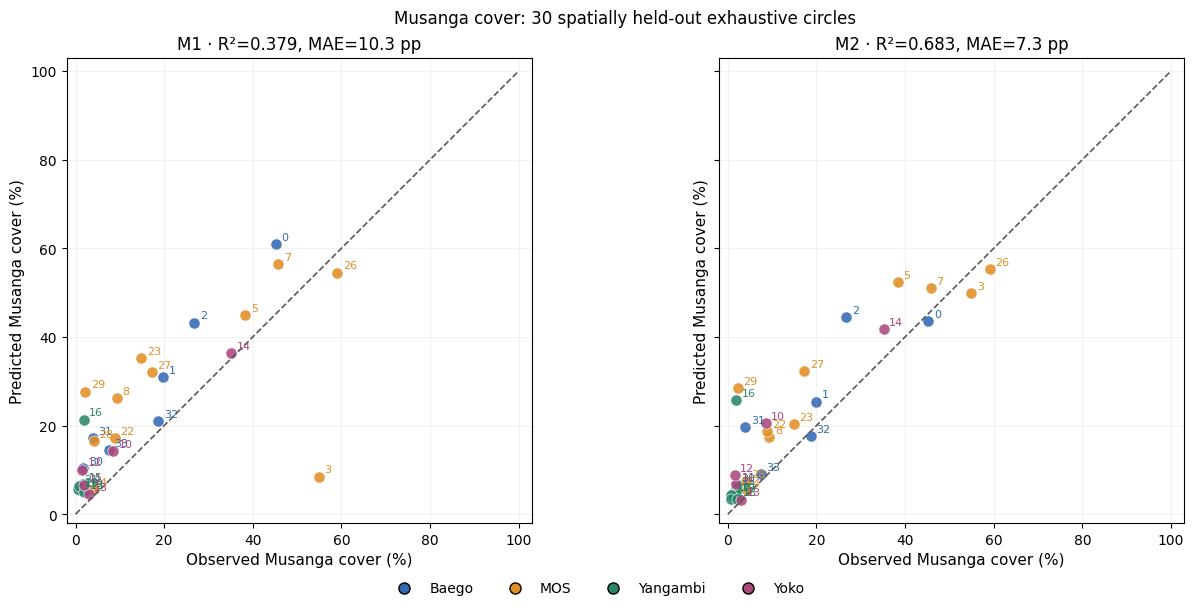

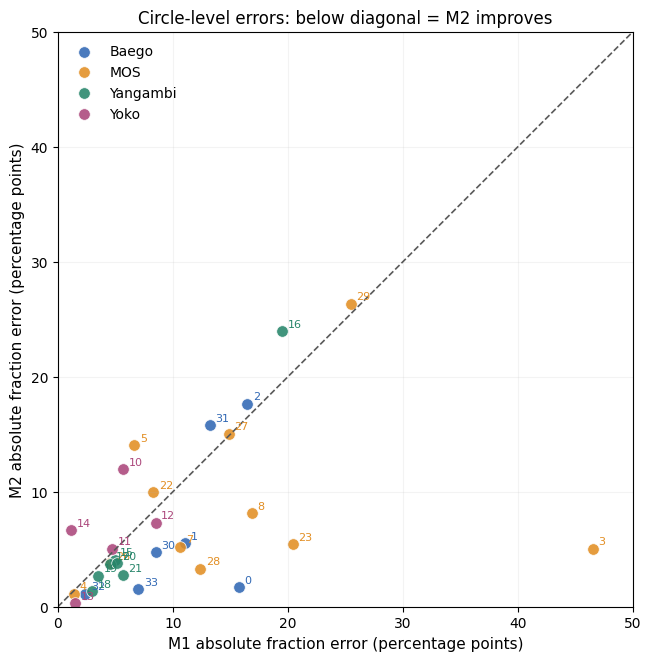

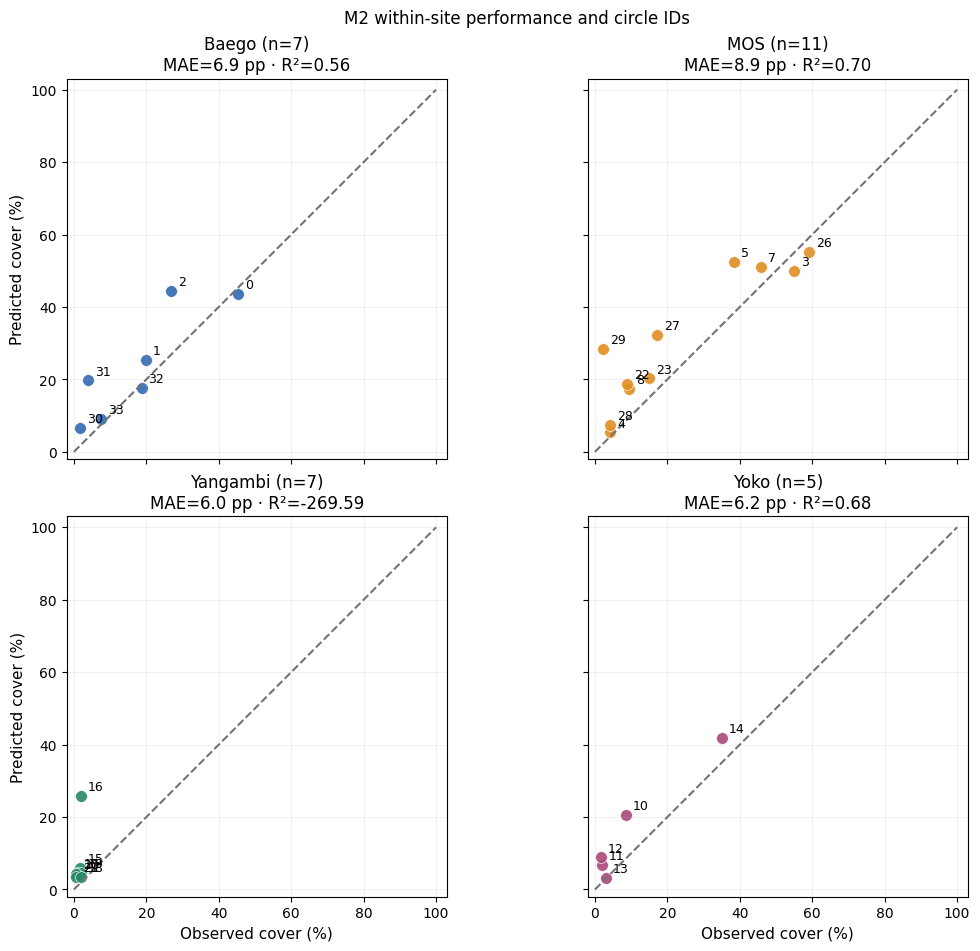

=== Spatial fold metrics (descriptive variability; n=3 folds) ===


,model,fold,n,R2,MAE_pp,RMSE_pp,pixel_F1,pixel_IoU,RPD
0,M1,0,11,0.640,10.332,11.856,0.609,0.437,1.748
1,M1,1,9,0.122,7.113,10.161,0.541,0.371,1.132
2,M1,2,10,-0.018,13.241,17.984,0.311,0.184,1.045
3,M2,0,11,0.895,5.240,6.390,0.719,0.561,3.243
4,M2,1,9,0.261,5.474,9.324,0.718,0.560,1.233
5,M2,2,10,0.472,11.200,12.952,0.382,0.236,1.450


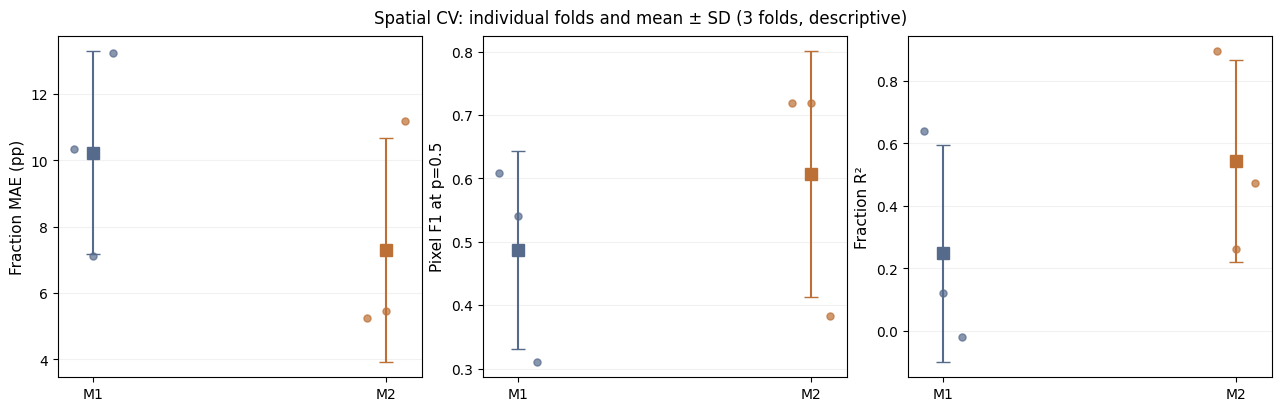

Saved metric CSVs and publication figures to: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34/figures


In [9]:
# NB02B Block 07: publication figures + metric audit; NO model training
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from IPython.display import display

REPORT_DIR=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34'
FIG_DIR=REPORT_DIR/'figures'
FIG_DIR.mkdir(parents=True,exist_ok=True)
READ=REPORT_DIR/'02B_spatialCV_all30_paired.csv'
assert READ.exists(),f'Run NB02B CV first: {READ}'
d=pd.read_csv(READ)
required={'model','site','circle_id','fold','observed_fraction','predicted_fraction','tp','fp','fn'}
assert required.issubset(d.columns),required-set(d.columns)
assert len(d)==60 and d.groupby('model').circle_id.nunique().to_dict()=={'M1':30,'M2':30}
assert not d.duplicated(['model','circle_id']).any()
assert d.groupby(['model','fold']).circle_id.nunique().min()>=1
assert sorted(d.fold.unique())==[0,1,2]

site_order=['Baego','MOS','Yangambi','Yoko']
colors={'Baego':'#3168B4','MOS':'#E28E23','Yangambi':'#27856A','Yoko':'#AB477B'}
symbols={'M1':'o','M2':'^'}
models=['M1','M2']
plt.rcParams.update({'font.size':10,'axes.titlesize':12,'axes.labelsize':11,
                     'savefig.dpi':200,'pdf.fonttype':42})
def savefig(fig,name):
    for suffix in ('png','pdf'):
        fig.savefig(FIG_DIR/(name+'.'+suffix),dpi=220,bbox_inches='tight')
    plt.show()
    plt.close(fig)
def fraction_metrics(sub):
    yy=sub.observed_fraction.to_numpy(float)
    pp=sub.predicted_fraction.to_numpy(float)
    error=pp-yy
    rmse=float(np.sqrt(np.mean(error**2)))
    sd=float(np.std(yy,ddof=1)) if len(yy)>1 else np.nan
    iqr=float(np.percentile(yy,75)-np.percentile(yy,25))
    value_range=float(np.max(yy)-np.min(yy))
    slope,intercept=np.polyfit(yy,pp,1) if len(yy)>1 and sd>0 else (np.nan,np.nan)
    tp,fp,fn=(float(sub[k].sum()) for k in ('tp','fp','fn'))
    return dict(n=len(sub),R2=float(r2_score(yy,pp)) if len(yy)>1 and sd>0 else np.nan,
                MAE_pp=float(np.mean(abs(error))),RMSE_pp=rmse,bias_pp=float(np.mean(error)),
                observed_sd_pp=sd,observed_IQR_pp=iqr,
                RPD=sd/rmse if rmse>0 else np.nan,
                RPIQ=iqr/rmse if rmse>0 else np.nan,
                nRMSE_range=rmse/value_range if value_range>0 else np.nan,
                calibration_slope=float(slope),calibration_intercept_pp=float(intercept),
                pixel_F1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,
                pixel_IoU=tp/(tp+fp+fn) if tp+fp+fn else np.nan,
                pixel_precision=tp/(tp+fp) if tp+fp else np.nan,
                pixel_recall=tp/(tp+fn) if tp+fn else np.nan)
metric_rows=[]
for model in models:
    sub=d[d.model==model]
    metric_rows.append(dict(model=model,site='ALL',**fraction_metrics(sub)))
    for site in site_order:
        metric_rows.append(dict(model=model,site=site,
                                **fraction_metrics(sub[sub.site==site])))
METRICS=pd.DataFrame(metric_rows)
METRICS.to_csv(REPORT_DIR/'02B_publication_performance_summary.csv',index=False)
print('=== Fraction cover, spatial F1/IoU, RPD and RPIQ ===')
display(METRICS.round(3))

left=d[d.model=='M1'].set_index('circle_id')
right=d[d.model=='M2'].set_index('circle_id')
assert left.index.is_unique and right.index.is_unique and set(left.index)==set(right.index)
assert (left.loc[right.index,'site'].to_numpy()==right.site.to_numpy()).all()
assert (left.loc[right.index,'fold'].to_numpy()==right.fold.to_numpy()).all()
paired=pd.DataFrame({
    'circle_id':right.index,
    'site':right.site.values,'fold':right.fold.values,
    'observed':right.observed_fraction.values,
    'pred_M1':left.loc[right.index,'predicted_fraction'].values,
    'pred_M2':right.predicted_fraction.values})
assert np.allclose(paired.observed,left.loc[right.index,'observed_fraction'],atol=0.02)
paired['error_M1']=paired.pred_M1-paired.observed
paired['error_M2']=paired.pred_M2-paired.observed
paired['abs_error_M1']=abs(paired.error_M1)
paired['abs_error_M2']=abs(paired.error_M2)
paired['improvement_pp']=paired.abs_error_M1-paired.abs_error_M2  # positive = M2 better
paired.sort_values(['site','circle_id']).to_csv(
    REPORT_DIR/'02B_publication_paired_circle_errors.csv',index=False)
print('M2 lower absolute error in',int((paired.improvement_pp>0).sum()),'of 30 circles.')

# Figure 1: two-panel site-coloured scatter, annotated by circle number
fig,axes=plt.subplots(1,2,figsize=(13,6),sharex=True,sharey=True,layout='constrained')
for ax,model in zip(axes,models):
    sub=d[d.model==model]
    m=METRICS[(METRICS.model==model)&(METRICS.site=='ALL')].iloc[0]
    for site in site_order:
        ss=sub[sub.site==site]
        ax.scatter(ss.observed_fraction,ss.predicted_fraction,
                   s=65,color=colors[site],alpha=.87,edgecolors='white',linewidths=.5)
        for q in ss.itertuples(index=False):
            ax.annotate(str(int(q.circle_id)),(q.observed_fraction,q.predicted_fraction),
                        xytext=(4,3),textcoords='offset points',fontsize=8,color=colors[site])
    ax.plot([0,100],[0,100],ls='--',lw=1.2,color='0.35')
    ax.set(xlim=(-2,103),ylim=(-2,103),aspect='equal',xlabel='Observed Musanga cover (%)',
           ylabel='Predicted Musanga cover (%)',
           title=f'{model} · R²={m.R2:.3f}, MAE={m.MAE_pp:.1f} pp')
    ax.grid(alpha=.16)
legend=[Line2D([0],[0],marker='o',color='none',markerfacecolor=colors[s],
               markersize=8,label=s) for s in site_order]
fig.legend(handles=legend,loc='outside lower center',ncol=4,frameon=False)
fig.suptitle('Musanga cover: 30 spatially held-out exhaustive circles')
savefig(fig,'fig01_observed_predicted_M1_M2_sites')

# Figure 2: paired absolute error, site colours and circle IDs
fig,ax=plt.subplots(figsize=(7,6.5),layout='constrained')
hi=float(np.ceil(max(paired.abs_error_M1.max(),paired.abs_error_M2.max())+3))
for site in site_order:
    ss=paired[paired.site==site]
    ax.scatter(ss.abs_error_M1,ss.abs_error_M2,s=70,color=colors[site],alpha=.88,
               label=site,edgecolor='white',linewidth=.6)
    for q in ss.itertuples(index=False):
        ax.annotate(str(int(q.circle_id)),(q.abs_error_M1,q.abs_error_M2),
                    xytext=(4,3),textcoords='offset points',fontsize=8,color=colors[site])
ax.plot([0,hi],[0,hi],ls='--',color='0.35',lw=1.2)
ax.set(xlim=(0,hi),ylim=(0,hi),aspect='equal',
       xlabel='M1 absolute fraction error (percentage points)',
       ylabel='M2 absolute fraction error (percentage points)',
       title='Circle-level errors: below diagonal = M2 improves')
ax.legend(frameon=False);ax.grid(alpha=.15)
savefig(fig,'fig02_paired_absolute_errors')

# Figure 3: per-site faceted scatter for M2, with consistent 1:1 axes
fig,axes=plt.subplots(2,2,figsize=(10.4,9.4),sharex=True,sharey=True,layout='constrained')
for ax,site in zip(axes.flat,site_order):
    ss=d[(d.model=='M2')&(d.site==site)]
    ms=METRICS[(METRICS.model=='M2')&(METRICS.site==site)].iloc[0]
    ax.scatter(ss.observed_fraction,ss.predicted_fraction,color=colors[site],
               s=72,alpha=.9,edgecolor='white',linewidths=.5)
    for q in ss.itertuples(index=False):
        ax.annotate(str(int(q.circle_id)),(q.observed_fraction,q.predicted_fraction),
                    xytext=(5,4),textcoords='offset points',fontsize=9)
    ax.plot([0,100],[0,100],ls='--',color='0.45')
    ax.set(xlim=(-2,103),ylim=(-2,103),aspect='equal',
           title=f'{site} (n={len(ss)})\nMAE={ms.MAE_pp:.1f} pp · R²={ms.R2:.2f}')
    ax.grid(alpha=.17)
for ax in axes[-1,:]:ax.set_xlabel('Observed cover (%)')
for ax in axes[:,0]:ax.set_ylabel('Predicted cover (%)')
fig.suptitle('M2 within-site performance and circle IDs')
savefig(fig,'fig03_M2_site_facets')

# Figure 4: three independent fold metrics (points), fold mean ± descriptive SD
fold_rows=[]
for (model,fold),ss in d.groupby(['model','fold']):
    fold_rows.append(dict(model=model,fold=int(fold),**fraction_metrics(ss)))
FOLD_METRICS=pd.DataFrame(fold_rows).sort_values(['model','fold'])
FOLD_METRICS.to_csv(REPORT_DIR/'02B_publication_fold_metrics.csv',index=False)
print('=== Spatial fold metrics (descriptive variability; n=3 folds) ===')
display(FOLD_METRICS[['model','fold','n','R2','MAE_pp','RMSE_pp','pixel_F1','pixel_IoU','RPD']].round(3))
fig,axes=plt.subplots(1,3,figsize=(12.7,4),layout='constrained')
for ax,(metric,label) in zip(axes,[('MAE_pp','Fraction MAE (pp)'),
                                    ('pixel_F1','Pixel F1 at p=0.5'),
                                    ('R2','Fraction R²')]):
    for ix,model in enumerate(models):
        values=FOLD_METRICS[FOLD_METRICS.model==model][metric].to_numpy(float)
        ax.errorbar(ix,float(values.mean()),yerr=float(values.std(ddof=1)),
                    fmt='s',markersize=8,capsize=5,color=['#566A8C','#BC7035'][ix])
        ax.scatter(np.full(3,ix)+np.array([-.065,0,.065]),values,
                   marker='o',s=26,color=['#566A8C','#BC7035'][ix],alpha=.7)
    ax.set_xticks([0,1],models);ax.set_ylabel(label);ax.grid(axis='y',alpha=.17)
fig.suptitle('Spatial CV: individual folds and mean ± SD (3 folds, descriptive)')
savefig(fig,'fig04_fold_variability')

print('Saved metric CSVs and publication figures to:',FIG_DIR)


In [13]:
# NB02B: sensitivity analysis for visually under-annotated Yangambi circle 16.
# Independent of prior notebook variables; read the existing held-out CSV.
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from IPython.display import display
ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
                         Path('/content/drive/MyDrive/Musanga/Final')] if p.is_dir()),None)
assert ROOT is not None,'Mount Google Drive first.'
REPORT=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34'
SCORES_FILE=REPORT/'02B_spatialCV_all30_paired.csv'
assert SCORES_FILE.exists(),('Run spatial CV evaluation before sensitivity analysis:',SCORES_FILE)
reference_manifest=ROOT/'Outputs/V3_1/00_input_audit/00_input_manifest.json'
import json
A_29=json.loads(reference_manifest.read_text())
assert A_29['reference_version']=='KVO_field_final',(
    'Expected KVO field-grounded reference; found',A_29['reference_version'])
s=pd.read_csv(SCORES_FILE)
required={'model','site','fold','circle_id','observed_fraction','predicted_fraction','tp','fp','fn'}
assert required.issubset(s.columns),sorted(required-set(s.columns))
assert s.groupby('model').circle_id.nunique().to_dict()=={'M1':30,'M2':30}
assert not s.duplicated(['model','circle_id']).any()
assert set(s.loc[s.circle_id==16,'site'])=={'Yangambi'},'Circle 16 site mismatch'
assert set(s.loc[s.circle_id==16,'model'])=={'M1','M2'}
assert s.circle_id.nunique()==30
# Check the CSV belongs to this reference; prevent accidentally analysing
# predictions saved for the previous Nadine-v2 dataset.
v3_1_manifest=REPORT/'02B_latest_reference_version.json'
assert v3_1_manifest.exists(),'Missing saved evaluation provenance'
saved=json.loads(v3_1_manifest.read_text())
assert Path(saved['exhaustive_source']).resolve()==Path(
    A_29['exhaustive_annotations']['positive_polygons']).resolve(),(
        'Saved results belong to another annotation file; rerun KVO CV.')
assert saved['circles']==30

def perf29(g):
    obs=g.observed_fraction.to_numpy(float)
    pred=g.predicted_fraction.to_numpy(float)
    err=pred-obs
    rmse=float(np.sqrt(np.mean(err**2)))
    sd=float(np.std(obs,ddof=1)) if len(g)>1 else np.nan
    iqr=float(np.percentile(obs,75)-np.percentile(obs,25))
    rng=float(np.ptp(obs))
    slope,intercept=(np.polyfit(obs,pred,1) if len(g)>1 and sd>0 else (np.nan,np.nan))
    tp,fp,fn=(int(g[k].sum()) for k in ['tp','fp','fn'])
    return dict(n=len(g),R2=float(r2_score(obs,pred)) if len(g)>1 and sd>0 else np.nan,
        MAE_pp=float(np.mean(np.abs(err))),RMSE_pp=rmse,
        bias_pp=float(np.mean(err)),observed_sd_pp=sd,
        observed_IQR_pp=iqr,RPD=sd/rmse if rmse>0 else np.nan,
        RPIQ=iqr/rmse if rmse>0 else np.nan,
        nRMSE_range=rmse/rng if rng>0 else np.nan,
        calibration_slope=float(slope),calibration_intercept_pp=float(intercept),
        pixel_F1=2*tp/max(1,2*tp+fp+fn),
        pixel_IoU=tp/max(1,tp+fp+fn),
        pixel_precision=tp/max(1,tp+fp),pixel_recall=tp/max(1,tp+fn))

rows=[]
for cohort,subset in [('all_30',s),('exclude_circle_16',s[s.circle_id!=16])]:
    for model in ['M1','M2']:
        t=subset[subset.model==model]
        for site in ['ALL','Baego','MOS','Yangambi','Yoko']:
            g=t if site=='ALL' else t[t.site==site]
            rows.append(dict(cohort=cohort,model=model,site=site,**perf29(g)))
results29=pd.DataFrame(rows)
assert set(results29[results29.cohort=='exclude_circle_16'].query("site=='ALL'").n)=={29}
out=REPORT/'02B_sensitivity_excluding_circle16'
out.mkdir(parents=True,exist_ok=True)
results29.to_csv(out/'circle16_all30_vs_29_summary.csv',index=False)
base=results29[results29.cohort=='all_30'].set_index(['model','site'])
cut=results29[results29.cohort=='exclude_circle_16'].set_index(['model','site'])
delta=(cut[['R2','MAE_pp','RMSE_pp','bias_pp','RPD','RPIQ','pixel_F1',
            'pixel_IoU','pixel_precision','pixel_recall']]-
       base[['R2','MAE_pp','RMSE_pp','bias_pp','RPD','RPIQ','pixel_F1',
             'pixel_IoU','pixel_precision','pixel_recall']]).add_prefix('delta_')
comparison=base[['n','R2','MAE_pp','RMSE_pp','bias_pp','pixel_F1','pixel_IoU']].add_prefix('all30_').join(
    cut[['n','R2','MAE_pp','RMSE_pp','bias_pp','pixel_F1','pixel_IoU']].add_prefix('excl16_')).join(delta)
comparison.reset_index().to_csv(out/'circle16_change_from_30.csv',index=False)
print('=== SENSITIVITY: full 30 vs excluding circle 16 (29 circles) ===')
display(results29[results29.site.isin(['ALL','Yangambi'])][
    ['cohort','model','site','n','R2','MAE_pp','RMSE_pp','bias_pp',
     'RPD','RPIQ','pixel_F1','pixel_IoU','pixel_precision','pixel_recall']
].round(3))
print('=== All sites, 29 circles (M1 versus M2) ===')
display(results29[(results29.cohort=='exclude_circle_16') &
                   (results29.site!='ALL')].round(3))
print('=== 29 minus 30 (positive delta_F1 and negative delta_MAE mean improved agreement) ===')
display(delta.reset_index().round(3))
m1=s[s.model=='M1'].set_index('circle_id')
m2=s[s.model=='M2'].set_index('circle_id')
ids=[i for i in sorted(m1.index) if i!=16]
errors1=(m1.loc[ids,'predicted_fraction']-m1.loc[ids,'observed_fraction']).abs()
errors2=(m2.loc[ids,'predicted_fraction']-m2.loc[ids,'observed_fraction']).abs()
print('M2 improves cover MAE in',int((errors2<errors1).sum()),'of 29 retained circles')
print('Saved sensitivity tables to',out)


=== SENSITIVITY: full 30 vs excluding circle 16 (29 circles) ===


,cohort,model,site,n,R2,MAE_pp,RMSE_pp,bias_pp,RPD,RPIQ,pixel_F1,pixel_IoU,pixel_precision,pixel_recall
0,all_30,M1,ALL,30,0.379,10.336,13.796,6.934,1.290,1.284,0.478,0.314,0.395,0.605
3,all_30,M1,Yangambi,7,-213.899,6.599,8.484,6.599,0.074,0.127,0.250,0.143,0.162,0.547
5,all_30,M2,ALL,30,0.683,7.297,9.847,6.519,1.808,1.799,0.576,0.405,0.460,0.772
8,all_30,M2,Yangambi,7,-269.592,6.044,9.520,6.044,0.066,0.113,0.309,0.183,0.201,0.676
10,exclude_circle_16,M1,ALL,29,0.409,10.020,13.557,6.502,1.324,1.325,0.517,0.349,0.456,0.597
13,exclude_circle_16,M1,Yangambi,6,-57.713,4.451,4.546,4.451,0.143,0.245,0.294,0.172,0.212,0.481
15,exclude_circle_16,M2,ALL,29,0.741,6.723,8.975,5.919,1.999,2.001,0.649,0.480,0.563,0.766
18,exclude_circle_16,M2,Yangambi,6,-28.136,3.063,3.203,3.063,0.203,0.348,0.482,0.318,0.396,0.617


=== All sites, 29 circles (M1 versus M2) ===


,cohort,model,site,n,R2,MAE_pp,RMSE_pp,bias_pp,observed_sd_pp,observed_IQR_pp,RPD,RPIQ,nRMSE_range,calibration_slope,calibration_intercept_pp,pixel_F1,pixel_IoU,pixel_precision,pixel_recall
11,exclude_circle_16,M1,Baego,7,0.323,10.624,11.603,10.624,15.236,17.592,1.313,1.516,0.267,1.159,7.815,0.658,0.490,0.565,0.787
12,exclude_circle_16,M1,MOS,11,0.121,15.269,19.383,5.992,21.680,35.510,1.118,1.832,0.341,0.419,19.660,0.575,0.403,0.564,0.586
13,exclude_circle_16,M1,Yangambi,6,-57.713,4.451,4.546,4.451,0.650,1.114,0.143,0.245,3.238,-0.218,6.047,0.294,0.172,0.212,0.481
14,exclude_circle_16,M1,Yoko,5,0.841,4.311,5.105,4.311,14.328,6.730,2.806,1.318,0.152,0.878,5.536,0.527,0.358,0.509,0.547
16,exclude_circle_16,M2,Baego,7,0.556,6.858,9.403,6.048,15.236,17.592,1.620,1.871,0.216,0.869,8.365,0.748,0.597,0.683,0.827
17,exclude_circle_16,M2,MOS,11,0.704,8.851,11.242,7.246,21.680,35.510,1.929,3.159,0.198,0.783,12.352,0.750,0.599,0.680,0.835
18,exclude_circle_16,M2,Yangambi,6,-28.136,3.063,3.203,3.063,0.650,1.114,0.203,0.348,2.281,0.262,4.030,0.482,0.318,0.396,0.617
19,exclude_circle_16,M2,Yoko,5,0.677,6.246,7.287,6.246,14.328,6.730,1.966,0.924,0.217,1.055,5.696,0.621,0.451,0.528,0.755


=== 29 minus 30 (positive delta_F1 and negative delta_MAE mean improved agreement) ===


,model,site,delta_R2,delta_MAE_pp,delta_RMSE_pp,delta_bias_pp,delta_RPD,delta_RPIQ,delta_pixel_F1,delta_pixel_IoU,delta_pixel_precision,delta_pixel_recall
0,M1,ALL,0.030,-0.316,-0.239,-0.433,0.033,0.041,0.039,0.035,0.061,-0.008
1,M1,Baego,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,M1,MOS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,M1,Yangambi,156.186,-2.148,-3.937,-2.148,0.069,0.118,0.044,0.030,0.050,-0.066
4,M1,Yoko,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,M2,ALL,0.057,-0.574,-0.872,-0.601,0.192,0.203,0.073,0.076,0.103,-0.005
6,M2,Baego,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
7,M2,MOS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,M2,Yangambi,241.456,-2.982,-6.317,-2.982,0.137,0.235,0.173,0.135,0.196,-0.059
9,M2,Yoko,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


M2 improves cover MAE in 20 of 29 retained circles
Saved sensitivity tables to /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34/02B_sensitivity_excluding_circle16


## 08 — Final production M2 trained with all 30 exhaustive circles (run separately)

**Purpose:** After CV model comparison is frozen, train **one** production ResNet18 M2 on native RGB using all 30 included exhaustive circles and all eligible partial labels. Preserve the published 3-fold CV checkpoints and results. This section uses *every eligible candidate window from NB01*, rather than the fold-specific train partitions. It changes neither NB02B CV outputs nor evaluation metrics. Run cells 01–05 to load definitions, **skip** the expensive Section 06 CV loop, then run this Section 08 only.

**Training:** same original M2 model, seed, augmentation, optimizer, learning rate, loss, batch size and 25 epochs. Same window cap rules by mosaic/type, but newly combined all-circle training set. Freeze model selection before this refit. The final model has **no independent held-out test observations**. Its performance must be described with the preceding NB02B spatial-CV results, not by rescoring training circles.

**Outputs:** `Outputs/V3_1/02B_spatial3fold_no_MOS34/final_all30_M2/` with a new training-chip cache, a versioned final checkpoint, loss per epoch, selection manifest and source hashes. This section deliberately does **not** run inference or overwrite any CV checkpoint.


In [12]:
# FINAL PRODUCTION REFIT: all 30 circles, NO heldout evaluation and NO CV rerun.
import gc,hashlib,json,time
from pathlib import Path
from torch.utils.data import DataLoader

assert len(links)==30 and links.circle_id.nunique()==30
assert EXHAUSTIVE_SHA==shapefile_content_signature(EXHAUSTIVE_SOURCE),(
    "Exhaustive polygons modified since definition; reload from first cells")
FINAL_ROOT=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34/final_all30_M2'
FINAL_ROOT.mkdir(parents=True,exist_ok=True)
FINAL_CROP_DIR=FINAL_ROOT/'chips'
FINAL_CROP_DIR.mkdir(exist_ok=True)
FINAL_EPOCHS=EPOCHS
assert FINAL_EPOCHS==25 and CROP==256 and BATCH==8 and SEED==20261016
# Establish exact annotation coverage for each source raster.
HOLDOUT=set()
DEV=set(links.circle_id.astype(int))
assert len(DEV)==30 and len(HOLDOUT)==0
for name,d in geo.items():
    cs=circles.to_crs(d['crs'])
    d['dev_circles']=cs[cs.original_row.isin(DEV)]
    BLOCKED[name]=[]
# Explicit all-circle candidate selection; do NOT use NB01 fold train flags.
elig=candidate[candidate.kind.isin(['partial','exhaustive'])].copy()
assert len(elig)>0
assert elig[elig.kind=='exhaustive'].circle_id.isin(DEV).all()
all_circles_in_candidates=set(elig.loc[elig.kind=='exhaustive','circle_id'].astype(int))
assert all_circles_in_candidates==DEV,(
    'Some exhaustive circles have no training candidates:',sorted(DEV-all_circles_in_candidates))
selected_parts=[]
for (name,kind),group in elig.groupby(['mosaic','kind']):
    cap=(MAX_PARTIAL_PER_MOSAIC*(3 if geo[name]['site']=='MOS' else 1)
         if kind=='partial' else MAX_EXHAUSTIVE_PER_SITE)
    selected_parts.append(group.sample(n=min(cap,len(group)),random_state=SEED))
selected=pd.concat(selected_parts,ignore_index=True)
assert set(selected[selected.kind=='exhaustive'].circle_id.astype(int))==DEV,(
    'Window cap dropped all windows for a circle; must inspect before training')
assert selected['mosaic'].isin(mosaics).all()
print('Final all-30 candidate selection:',selected.groupby(['site','kind']).size().to_dict(),flush=True)

sources=[REF/'01_cv_window_manifest.csv',REF/'01_circle_spatial_folds.csv',
         REF/'01_candidate_windows.csv',
         ROOT/'Outputs/V3_1/00_input_audit/00_input_manifest.json',
         Path(A['exhaustive_annotations']['complete_roi_boundaries']),
         Path(A['roi']),EXHAUSTIVE_SOURCE]
selected_hash=hashlib.sha256(
    selected.sort_values(['mosaic','kind','row','col']).to_csv(index=False).encode()).hexdigest()
file_signature={}
for source in sources:
    file_signature[str(source)]=shapefile_content_signature(source)
image_signature={}
for name in sorted(mosaics):
    p=Path(geo[name]['path'])
    stat=p.stat()
    image_signature[str(p)]={'size':stat.st_size,'mtime_ns':stat.st_mtime_ns}
manifest=dict(version='NB02B_final_all30_M2_v1',architecture='ResNet18_UNet_ImageNet',
    image_input='native_RGB_divided_by_255_no_mean_std',circle_ids=sorted(DEV),
    exhaustive_annotations_sha256=EXHAUSTIVE_SHA,
    selected_windows_sha256=selected_hash,reference_files=file_signature,
    image_files=image_signature,crop=CROP,epochs=FINAL_EPOCHS,batch=BATCH,
    seed=SEED,lr=2e-4,weight_decay=1e-4,
    max_partial_per_mosaic=MAX_PARTIAL_PER_MOSAIC,
    max_exhaustive_per_site=MAX_EXHAUSTIVE_PER_SITE)
FINAL_KEY=hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()
FINAL_MODEL=FINAL_ROOT/f'M2_FINAL_all30_{FINAL_KEY[:20]}.pt'
FINAL_CACHE=FINAL_CROP_DIR/f'M2_FINAL_all30_{FINAL_KEY[:20]}.npz'
# Keyed manifests avoid collisions with the old Nadine-v2 all-30 refit.
# Old unversioned manifest/history remain untouched for reproducibility.
FINAL_MANIFEST=FINAL_ROOT/f'02B_final_all30_manifest_{FINAL_KEY[:20]}.json'
LEGACY_MANIFEST=FINAL_ROOT/'02B_final_all30_manifest.json'
FINAL_HISTORY=FINAL_ROOT/f'02B_final_all30_training_history_{FINAL_KEY[:20]}.csv'
if LEGACY_MANIFEST.exists():
    legacy=json.loads(LEGACY_MANIFEST.read_text())
    if legacy.get('training_key')!=FINAL_KEY:
        print('PRESERVING PREVIOUS V3_1 FINAL MANIFEST:',
              LEGACY_MANIFEST,'(different annotation fingerprint)',flush=True)
        print('New field-grounded checkpoint/manifest will be keyed:',FINAL_KEY[:20],flush=True)
if FINAL_MANIFEST.exists():
    previous=json.loads(FINAL_MANIFEST.read_text())
    assert previous.get('training_key')==FINAL_KEY,(
        'Keyed manifest fingerprint mismatch — inspect provenance',FINAL_MANIFEST)
else:
    FINAL_MANIFEST.write_text(json.dumps(dict(manifest,
        reference_version=A.get('reference_version'),
        training_key=FINAL_KEY,
        checkpoint=str(FINAL_MODEL),chip_cache=str(FINAL_CACHE),
        training_history=str(FINAL_HISTORY)),indent=2))
print('FINAL VERSIONED MANIFEST:',FINAL_MANIFEST,flush=True)
if FINAL_MODEL.exists():
    print('FINAL CHECKPOINT HIT (no retraining):',FINAL_MODEL,flush=True)
else:
    if FINAL_CACHE.exists():
        chips=_unpack_chips(FINAL_CACHE,FINAL_KEY)
        print('FINAL CACHE HIT:',len(chips),'chips',flush=True)
    else:
        chips=[]
        for name,group in selected.groupby('mosaic',sort=True):
            rows=list(group.itertuples(index=False))
            # Staging only if disk allows; this uses unchanged NB02B training_crop.
            with staged_mosaic(name):
                for offset in range(0,len(rows),100):
                    part=FINAL_CROP_DIR/f'{FINAL_KEY[:20]}_{Path(name).stem}_{offset:04d}.npz'
                    if part.exists():
                        block=_unpack_chips(part,FINAL_KEY)
                    else:
                        block=[q for rec in rows[offset:offset+100]
                               if (q:=training_crop(rec,'M2')) is not None]
                        if block:_pack_chips(part,block,FINAL_KEY)
                    chips.extend(block)
                    print('FINAL cache',name,min(offset+100,len(rows)),
                          '/',len(rows),'usable',len(block),flush=True)
        assert len(chips)>30,('Final cache too small',len(chips))
        _pack_chips(FINAL_CACHE,chips,FINAL_KEY)
        print('FINAL CACHED:',len(chips),'chips',flush=True)
    torch.manual_seed(SEED)
    model=ResNet18UNet().to(device)
    loader=DataLoader(CropDataset(chips),batch_size=BATCH,shuffle=True,
                      num_workers=0,pin_memory=True)
    optimizer=torch.optim.AdamW(model.parameters(),lr=2e-4,weight_decay=1e-4)
    scaler=torch.amp.GradScaler('cuda',enabled=(device=='cuda'))
    history=[]
    for epoch in range(FINAL_EPOCHS):
        model.train();losses=[];tic=time.perf_counter()
        for x,y,w in loader:
            x=x.to(device,non_blocking=True)
            y=y.to(device,non_blocking=True)
            w=w.to(device,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=(device=='cuda')):
                logits=model(x)
            loss=masked_loss(logits.float(),y,w)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            losses.append(float(loss.detach().cpu()))
        loss_epoch=float(np.mean(losses))
        assert np.isfinite(loss_epoch),('Nonfinite training loss',epoch)
        history.append(dict(epoch=epoch+1,masked_BCE=loss_epoch,
                            seconds=time.perf_counter()-tic))
        pd.DataFrame(history).to_csv(FINAL_HISTORY,index=False)
        print(f'FINAL ALL30 epoch {epoch+1:02d}/{FINAL_EPOCHS} '
              f'BCE={loss_epoch:.4f} {history[-1]["seconds"]:.1f}s',flush=True)
    temp=FINAL_MODEL.with_suffix('.partial.pt')
    torch.save(model.state_dict(),temp)
    temp.replace(FINAL_MODEL)
    del chips,model
    gc.collect();torch.cuda.empty_cache()
    print('FINAL TRAINING COMPLETE:',FINAL_MODEL,flush=True)
assert FINAL_MODEL.exists()
print('FINAL ALL30 M2 ready:',FINAL_MODEL)
print('Use this production checkpoint for NB03; do not report training-circle metrics as heldout.')


Final all-30 candidate selection: {('Baego', 'exhaustive'): 102, ('Baego', 'partial'): 250, ('MOS', 'exhaustive'): 87, ('MOS', 'partial'): 600, ('Yangambi', 'exhaustive'): 260, ('Yangambi', 'partial'): 250, ('Yoko', 'exhaustive'): 257, ('Yoko', 'partial'): 250}
PRESERVING PREVIOUS V3_1 FINAL MANIFEST: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34/final_all30_M2/02B_final_all30_manifest.json (different annotation fingerprint)
New field-grounded checkpoint/manifest will be keyed: e771b117e742eeec5851
FINAL VERSIONED MANIFEST: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34/final_all30_M2/02B_final_all30_manifest_e771b117e742eeec5851.json
STAGE SKIPPED Baego.tif: image 1.19 GB, free SSD 187.14 GB; using one persistent Drive handle
FINAL cache Baego.tif 100 / 352 usable 83
FINAL cache Baego.tif 200 / 352 usable 88
FINAL cache Baego.tif 300 / 352 usable 93
FINAL cache Baego.tif 352 / 352 usable 46
STAG

## 09 — Frozen model audit before any corrective refit
This block compares the actual cached pixel labels (positive and negative) in each spatial-CV training model versus the all-30 production refit, including site/kind strata, and reads saved training histories. **Do not retrain until the balance and convergence differences are interpreted.**


In [ ]:
# Section 09 — AUDIT ONLY. Run Section 01-05 and Section 08 setup first.
# Compare actual cached, supervised pixel compositions; no model fitting.
from collections import defaultdict
import pandas as pd, numpy as np, json
from pathlib import Path

BASE_OUT=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34'
assert FINAL_CACHE.exists(), ("Run the original final-all30 Section 08 setup first", FINAL_CACHE)
assert FINAL_MODEL.exists(), ("Frozen final model missing", FINAL_MODEL)
def chip_stats(chips, label):
    rows=[]
    for chip in chips:
        w=np.asarray(chip['weight'])>0
        y=np.asarray(chip['target'])>0.5
        pos=int((w&y).sum()); neg=int((w&~y).sum())
        rows.append(dict(model=label,site=chip['site'],kind=chip['kind'],
                         supervised=pos+neg,positive=pos,negative=neg))
    return pd.DataFrame(rows)

audit_parts=[]
full=_unpack_chips(FINAL_CACHE,FINAL_KEY)
audit_parts.append(chip_stats(full,'FINAL_ALL30'))
print('FINAL:',len(full),'chips',flush=True)
del full

# Fold-specific CV caches have exact original fingerprint suffixes.
# The fold-specific DEV/HOLDOUT settings are essential for cv_fingerprint.
for fold in (0,1,2):
    HOLDOUT=set(links.loc[links.fold==fold,'circle_id'].astype(int))
    DEV=set(links.loc[links.fold!=fold,'circle_id'].astype(int))
    key=cv_fingerprint(fold,'M2')
    file=CACHE_DIR/f'M2_fold{fold}_{key[:20]}.npz'
    assert file.is_file(),('Missing exact KVO M2 CV chip cache',fold,file)
    c=_unpack_chips(file,key)
    audit_parts.append(chip_stats(c,f'CV_FOLD_{fold}'))
    print('CV fold',fold,':',len(c),'chips',flush=True)
    del c

audit=pd.concat(audit_parts,ignore_index=True)
assert (audit.supervised>0).all()
group=(audit.groupby(['model','site','kind'],as_index=False)
       .agg(chips=('supervised','size'),supervised_pixels=('supervised','sum'),
            positive_pixels=('positive','sum'),negative_pixels=('negative','sum')))
group['positive_fraction']=group.positive_pixels/group.supervised_pixels
totals=(audit.groupby('model',as_index=False)
        .agg(chips=('supervised','size'),supervised_pixels=('supervised','sum'),
             positive_pixels=('positive','sum'),negative_pixels=('negative','sum')))
totals['positive_fraction']=totals.positive_pixels/totals.supervised_pixels
print('=== SITE AND SUPERVISION AUDIT ===')
display(group.round(4))
print('=== OVERALL SUPERVISION AUDIT ===')
display(totals.round(4))

history=[]
for fold in (0,1,2):
    f=BASE_OUT/f'fold_{fold}'/'M2_loss.csv'
    if f.exists():
        h=pd.read_csv(f)
        history.append(dict(model=f'CV_FOLD_{fold}',epochs=len(h),
                            first_BCE=float(h.masked_BCE.iloc[0]),
                            final_BCE=float(h.masked_BCE.iloc[-1]),
                            minimum_BCE=float(h.masked_BCE.min())))
h=pd.read_csv(FINAL_HISTORY)
history.append(dict(model='FINAL_ALL30',epochs=len(h),
                    first_BCE=float(h.masked_BCE.iloc[0]),
                    final_BCE=float(h.masked_BCE.iloc[-1]),
                    minimum_BCE=float(h.masked_BCE.min())))
print('=== TRAINING HISTORY ===')
display(pd.DataFrame(history).round(5))
AUDIT_DIR=FINAL_ROOT/'audit_no_training'
AUDIT_DIR.mkdir(exist_ok=True)
group.to_csv(AUDIT_DIR/'09_supervision_by_site_kind.csv',index=False)
totals.to_csv(AUDIT_DIR/'09_supervision_totals.csv',index=False)
pd.DataFrame(history).to_csv(AUDIT_DIR/'09_training_history.csv',index=False)
print('AUDIT COMPLETE; no checkpoints changed:',AUDIT_DIR)


## 10 — Corrected final M2: select duration on held-out circles, then refit all 30
Pilot train on CV fold 0 training chips; evaluate at epochs 5,10,15,20,25 on held-out fold 0 circles. Select epoch by mean absolute fraction error without using all-30 final model circles for model selection. Train a separate versioned final M2 on all 30 using selected duration. **This is a one-fold epoch-selection pilot, not independent final-model validation; the resulting all-30 checkpoint still requires cautious QA.** Existing models remain frozen.


In [ ]:
# SECTION 10 — Versioned corrected refit, with spatial validation epoch selection.
# Prerequisites: execute sections 01–05 and 08 (checkpoint/cache HIT) first.
# DO NOT run section 06, and DO NOT overwrite previous models.
import copy, gc, hashlib, json, time
from pathlib import Path
from torch.utils.data import DataLoader
assert FINAL_MODEL.is_file() and FINAL_CACHE.is_file(), 'Section 08 must show CHECKPOINT HIT'
assert len(links)==30 and EXHAUSTIVE_SHA==manifest['exhaustive_annotations_sha256']
assert set(links.fold.astype(int))=={0,1,2}
OUT=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34'
SELECTION_FOLD=0
EPOCH_CANDIDATES=[5,10,15,20,25]
VALID_WINDOWS_PER_CIRCLE=8
PILOT_SEED=SEED+101
REFIT_SEED=SEED+102
NEW_ROOT=OUT/'final_all30_M2_v2_spatial_epoch'
NEW_ROOT.mkdir(parents=True,exist_ok=True)
# Validation examples: deterministic equal number of native 256px windows per entire
# held-out circle, no overlap with training circles, same raw RGB and KVO mask.
val_ids=sorted(links.loc[links.fold==SELECTION_FOLD,'circle_id'].astype(int))
HOLDOUT=set(val_ids)
DEV=set(links.loc[links.fold!=SELECTION_FOLD,'circle_id'].astype(int))
assert HOLDOUT.isdisjoint(DEV)
for name,d in geo.items():
    cs=circles.to_crs(d['crs'])
    d['dev_circles']=cs[cs.original_row.isin(DEV)]
    BLOCKED[name]=[g.buffer(15) for g in cs[cs.original_row.isin(HOLDOUT)].geometry]
    d['roi_local']=roi.to_crs(d['crs'])
    d['positive_local']=positive.to_crs(d['crs'])
VAL_WINDOWS=pd.read_csv(REF/'01_candidate_windows.csv')
VAL_WINDOWS=VAL_WINDOWS[(VAL_WINDOWS.kind=='exhaustive')&
                         (VAL_WINDOWS.circle_id.isin(val_ids))]
validation={}
for cid in val_ids:
    own=links.loc[links.circle_id==cid].iloc[0]
    name=own.mosaic
    d=geo[name]
    cg=circles[circles.original_row==cid].to_crs(d['crs'])
    rows=VAL_WINDOWS[(VAL_WINDOWS.circle_id==cid)&(VAL_WINDOWS.mosaic==name)]
    assert len(rows)>=VALID_WINDOWS_PER_CIRCLE,(cid,len(rows))
    chosen=rows.sample(n=VALID_WINDOWS_PER_CIRCLE,random_state=SEED+cid)
    examples=[]
    with rasterio.open(d['path']) as src:
        for z in chosen.itertuples(index=False):
            win=Window(int(z.col),int(z.row),int(z.width),int(z.height))
            # NB01 exhaustive evaluation windows are 512x512; NB02B's U-Net\n            # evaluates them at native size. 256x256 is training-chip size only.\n            assert int(win.width)>0 and int(win.height)>0,(cid,win)
            raw=src.read([1,2,3],window=win,masked=True)
            rgb=raw.filled(0).astype('float32')/255.
            valid=~np.any(np.ma.getmaskarray(raw),axis=0)
            a=raw.filled(0)
            valid &= np.any(a!=0,axis=0)&np.any(a!=255,axis=0)
            valid &= ~((a[0]==0)&(a[1]==0)&(a[2]==255))
            mask=burn_window(cg.geometry,name,win)&burn_window(d['roi_local'].geometry,name,win)&valid
            truth=burn_window(d['positive_local'].geometry,name,win)
            if mask.sum()>=1000:
                examples.append((np.ascontiguousarray(rgb),mask,truth))
    assert len(examples)>=3,(cid,len(examples))
    validation[cid]=examples
print('Spatial-validation circles:',len(validation),'with window counts',
      {cid:len(v) for cid,v in validation.items()},flush=True)

def sample_validation_mae(net):
    net.eval()
    errors=[]
    with torch.inference_mode():
        for cid,examples in validation.items():
            sump=sumy=n=0.
            for rgb,mask,truth in examples:
                x=torch.from_numpy(rgb[None]).to(device)
                logits=net(x)[0]
                prob=torch.sigmoid(logits).cpu().numpy()
                sump+=float(prob[mask].sum())
                sumy+=float(truth[mask].sum())
                n+=int(mask.sum())
            errors.append(abs(100*(sump-sumy)/n))
    return float(np.mean(errors))
def train_epoch_model(net,chips,num_epochs,seed,logfile,validation_epochs=None):
    torch.manual_seed(seed)
    loader=DataLoader(CropDataset(chips),batch_size=BATCH,
                      shuffle=True,num_workers=0,pin_memory=True)
    optim=torch.optim.AdamW(net.parameters(),lr=2e-4,weight_decay=1e-4)
    scaler=torch.amp.GradScaler('cuda',enabled=(device=='cuda'))
    rows=[]
    for epoch in range(1,num_epochs+1):
        net.train(); losses=[];start=time.perf_counter()
        for x,y,w in loader:
            x=x.to(device);y=y.to(device);w=w.to(device)
            optim.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=(device=='cuda')):
                logits=net(x)
            loss=masked_loss(logits.float(),y,w)
            scaler.scale(loss).backward();scaler.step(optim);scaler.update()
            losses.append(float(loss.detach().cpu()))
        rec=dict(epoch=epoch,masked_BCE=float(np.mean(losses)),
                 seconds=round(time.perf_counter()-start,2))
        if validation_epochs and epoch in validation_epochs:
            rec['spatial_validation_MAE_pp']=sample_validation_mae(net)
        rows.append(rec)
        pd.DataFrame(rows).to_csv(logfile,index=False)
        print('Epoch',epoch,'/',num_epochs,'BCE',round(rec['masked_BCE'],4),
              'held-out MAE',rec.get('spatial_validation_MAE_pp','—'),flush=True)
    return pd.DataFrame(rows)

# Fingerprinted pilot and final model. Never overwrite, restart with existing artifacts.
pilot_payload=dict(version='M2_v2_spatial_epoch_pilot_1fold',
                   source_training_key=FINAL_KEY,source_reference_sha=EXHAUSTIVE_SHA,
                   selection_fold=SELECTION_FOLD,epoch_candidates=EPOCH_CANDIDATES,
                   validation_windows_per_circle=VALID_WINDOWS_PER_CIRCLE,
                   pilot_seed=PILOT_SEED,refit_seed=REFIT_SEED)
pilot_key=hashlib.sha256(json.dumps(pilot_payload,sort_keys=True).encode()).hexdigest()[:20]
pilot_history=NEW_ROOT/f'pilot_{pilot_key}_history.csv'
pilot_ckpt=NEW_ROOT/f'pilot_{pilot_key}_epoch25.pt'
if pilot_history.exists() and pilot_ckpt.exists():
    h=pd.read_csv(pilot_history)
    assert len(h)==25 and set(EPOCH_CANDIDATES).issubset(h.loc[
        h.spatial_validation_MAE_pp.notna(),'epoch'].astype(int))
    print('PILOT CACHE HIT',pilot_history,flush=True)
else:
    assert not pilot_history.exists() and not pilot_ckpt.exists(),(
        'Partial pilot detected; inspect rather than silently overwrite')
    key=cv_fingerprint(SELECTION_FOLD,'M2')
    cv_cache=CACHE_DIR/f'M2_fold{SELECTION_FOLD}_{key[:20]}.npz'
    assert cv_cache.exists(),('Exact KVO CV chips missing',cv_cache)
    pilot_chips=_unpack_chips(cv_cache,key)
    torch.manual_seed(PILOT_SEED)
    pilot=ResNet18UNet().to(device)
    h=train_epoch_model(pilot,pilot_chips,25,PILOT_SEED,pilot_history,EPOCH_CANDIDATES)
    temp=pilot_ckpt.with_suffix('.partial.pt')
    torch.save(pilot.state_dict(),temp);temp.replace(pilot_ckpt)
    del pilot,pilot_chips;gc.collect();torch.cuda.empty_cache()
selected=h[h.epoch.isin(EPOCH_CANDIDATES)].copy()
best=selected.sort_values(['spatial_validation_MAE_pp','epoch']).iloc[0]
BEST_EPOCH=int(best.epoch)
print('PRE-SELECTED FINAL TRAINING DURATION:',BEST_EPOCH,
      'epochs; held-out pilot MAE=',round(float(best.spatial_validation_MAE_pp),3))
# All 30 included for final refit. Baego circles are NOT used to choose final
# checkpoints after this stage; the duration is frozen from held-out pilot.
final_payload=dict(pilot_payload,version='M2_v2_spatial_epoch_final',
                   best_epoch=BEST_EPOCH,pilot_history_sha256=shapefile_content_signature(pilot_history))
new_key=hashlib.sha256(json.dumps(final_payload,sort_keys=True).encode()).hexdigest()[:20]
NEW_MODEL=NEW_ROOT/f'M2_FINAL_all30_v2_{new_key}.pt'
NEW_MANIFEST=NEW_ROOT/f'M2_FINAL_all30_v2_{new_key}.json'
NEW_HISTORY=NEW_ROOT/f'M2_FINAL_all30_v2_{new_key}_history.csv'
if NEW_MODEL.exists():
    assert NEW_MANIFEST.exists(),('Checkpoint missing provenance',NEW_MODEL)
    assert json.loads(NEW_MANIFEST.read_text())['recipe']==final_payload
    print('CORRECTED REFIT CHECKPOINT HIT:',NEW_MODEL)
else:
    assert not NEW_MANIFEST.exists() and not NEW_HISTORY.exists(),(
        'Partial final refit; inspect before retry')
    full_chips=_unpack_chips(FINAL_CACHE,FINAL_KEY)
    torch.manual_seed(REFIT_SEED)
    final=ResNet18UNet().to(device)
    final_h=train_epoch_model(final,full_chips,BEST_EPOCH,REFIT_SEED,NEW_HISTORY)
    tmp=NEW_MODEL.with_suffix('.partial.pt')
    torch.save(final.state_dict(),tmp);tmp.replace(NEW_MODEL)
    NEW_MANIFEST.write_text(json.dumps(dict(recipe=final_payload,
        checkpoint=str(NEW_MODEL),history=str(NEW_HISTORY),
        kvo_reference_sha256=EXHAUSTIVE_SHA,training_source_manifest=str(FINAL_MANIFEST),
        selection_note='One held-out fold pilot chose duration; final all30 not independently tested'),indent=2))
    del final,full_chips;gc.collect();torch.cuda.empty_cache()
print('NEW FINAL MODEL:',NEW_MODEL)
print('NEXT: evaluate on NB02B windows as IN-SAMPLE diagnostic; do not replace NB03 checkpoint until QA passes.')


## 11 — Diagnose M2 final overprediction on identical cached training chips
Read-only, full-precision inference on exactly the same 1,760 final training chips for the KVO CV-fold-0 model and both final checkpoints. Separates exhaustive vs partial data, each site, negative-class probabilities, and positive/negative BCE. **Descriptive in-sample diagnostics only**; does not replace held-out spatial CV.


In [ ]:
# SECTION 11 — READ-ONLY DIAGNOSTIC: common chips, exact same pixel masks
# Requires Sections 01–05, 08 and 10 completed. No training or checkpoint writes.
import numpy as np, pandas as pd, torch, gc
import torch.nn.functional as F
from pathlib import Path
from IPython.display import display

assert FINAL_CACHE.is_file() and NEW_MODEL.is_file()
assert EXHAUSTIVE_SHA==manifest['exhaustive_annotations_sha256']
assert (ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34/fold_0').is_dir()

# Compare two final models with the held-out fold-0 model ON THE SAME all-30 chips.
# Performance on these chips is descriptive/in-sample, not an independent CV metric.
cv0_path=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34/fold_0/M2_resnet18_spatialCV_3ee0e5ba7eea84591d7b.pt'
assert cv0_path.is_file(),cv0_path
checkpoints={'CV_fold0':cv0_path,'Final_v1':FINAL_MODEL,'Final_v2':NEW_MODEL}
chips=_unpack_chips(FINAL_CACHE,FINAL_KEY)
assert len(chips)==1760,('Unexpected final training cache',len(chips))
BATCH_AUDIT=8
allrows=[]
for model_name,checkpoint in checkpoints.items():
    model=ResNet18UNet().to(device)
    model.load_state_dict(torch.load(checkpoint,map_location='cpu',weights_only=True),strict=True)
    model.eval()
    for start in range(0,len(chips),BATCH_AUDIT):
        batch=chips[start:start+BATCH_AUDIT]
        x=torch.from_numpy(np.stack([q['image'].transpose(2,0,1) for q in batch]).astype('float32')).to(device)
        with torch.inference_mode():
            # Full float32 inference, consistent with NB02B evaluation
            logits=model(x)
            probs=torch.sigmoid(logits).cpu().numpy()
            losses=F.binary_cross_entropy_with_logits(
                logits,torch.from_numpy(np.stack([q['target'] for q in batch])).to(device),
                reduction='none').cpu().numpy()
        for j,q in enumerate(batch):
            valid=q['weight']>0
            pos=valid&(q['target']>0.5)
            neg=valid&~pos
            if not valid.any():continue
            allrows.append(dict(model=model_name,site=q['site'],kind=q['kind'],
                pos_n=int(pos.sum()),neg_n=int(neg.sum()),
                pos_pred_sum=float(probs[j][pos].sum()),
                neg_pred_sum=float(probs[j][neg].sum()),
                pos_loss_sum=float(losses[j][pos].sum()),
                neg_loss_sum=float(losses[j][neg].sum()),
                predicted_pos05=int(((probs[j]>=.5)&valid).sum()),
                true_pos=int(pos.sum()),supervised=int(valid.sum())))
        if start==0 or (start//BATCH_AUDIT+1)%50==0 or start+BATCH_AUDIT>=len(chips):
            print(model_name,min(start+BATCH_AUDIT,len(chips)),'/',len(chips),'chips',flush=True)
    del model;torch.cuda.empty_cache();gc.collect()

raw=pd.DataFrame(allrows)
summary=(raw.groupby(['model','site','kind'],as_index=False)
    .agg({k:'sum' for k in ['pos_n','neg_n','pos_pred_sum','neg_pred_sum',
          'pos_loss_sum','neg_loss_sum','predicted_pos05','true_pos','supervised']}))
summary['true_fraction']=summary.true_pos/summary.supervised
summary['predicted_fraction05']=summary.predicted_pos05/summary.supervised
summary['fraction_bias_pp']=100*(summary.predicted_fraction05-summary.true_fraction)
summary['mean_prob_on_positive']=summary.pos_pred_sum/summary.pos_n
summary['mean_prob_on_negative']=summary.neg_pred_sum/summary.neg_n
summary['positive_BCE']=summary.pos_loss_sum/summary.pos_n
summary['negative_BCE']=summary.neg_loss_sum/summary.neg_n
print('=== SUPERVISION-SOURCE ERROR AUDIT (IDENTICAL CACHED CHIPS) ===')
display(summary[['model','site','kind','supervised','true_fraction',
                 'predicted_fraction05','fraction_bias_pp','mean_prob_on_positive',
                 'mean_prob_on_negative','positive_BCE','negative_BCE']].round(4))
overall=(raw.groupby('model',as_index=False)
         .agg({k:'sum' for k in ['pos_n','neg_n','pos_pred_sum','neg_pred_sum',
                 'pos_loss_sum','neg_loss_sum','predicted_pos05','true_pos','supervised']}))
overall['true_fraction']=overall.true_pos/overall.supervised
overall['predicted_fraction05']=overall.predicted_pos05/overall.supervised
overall['bias_pp']=100*(overall.predicted_fraction05-overall.true_fraction)
overall['mean_prob_on_negative']=overall.neg_pred_sum/overall.neg_n
overall['negative_BCE']=overall.neg_loss_sum/overall.neg_n
print('=== OVERALL TRAINING-CHIP ERROR AUDIT ===')
display(overall[['model','true_fraction','predicted_fraction05','bias_pp',
                 'mean_prob_on_negative','negative_BCE']].round(4))
dest=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34/final_all30_M2_v2_spatial_epoch/audit_no_training'
dest.mkdir(parents=True,exist_ok=True)
summary.to_csv(dest/'11_source_error_audit.csv',index=False)
overall.to_csv(dest/'11_overall_error_audit.csv',index=False)
print('Saved audit to',dest,'; no model weights changed.')


## 12 — Baego training-chip spatial coverage and M2 v2 bias
Read-only diagnostic reconstructing actual usable final-all30 Baego chip footprints (expected 225 partial and 85 exhaustive) and measuring M2 v2 mean-probability bias separately on sampled versus unsampled pixels of the seven evaluation circles. This is an in-sample diagnostic and does **not** establish independent accuracy. No checkpoints are modified.


In [ ]:
# SECTION 12 — Baego: actual final-training-chip footprints versus unsampled circle pixels
# Read-only audit; no model training. Requires NB02B Sections 01–05, 08 and 10.
import numpy as np, pandas as pd, rasterio, torch, gc
from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box
from IPython.display import display

assert FINAL_CACHE.exists() and NEW_MODEL.exists()
# Reconstruct the precise Section 08 selection instead of relying on
# 'selected' (overwritten by Section 10's epoch-selection table).
eligible_final=candidate[candidate.kind.isin(['partial','exhaustive'])].copy()
assert eligible_final.loc[eligible_final.kind=='exhaustive','circle_id'].isin(
    links.circle_id).all()
final_parts=[]
for (mosaic,kind),group in eligible_final.groupby(['mosaic','kind']):
    cap=(MAX_PARTIAL_PER_MOSAIC*(3 if geo[mosaic]['site']=='MOS' else 1)
         if kind=='partial' else MAX_EXHAUSTIVE_PER_SITE)
    final_parts.append(group.sample(n=min(cap,len(group)),random_state=SEED))
selected_training_windows=pd.concat(final_parts,ignore_index=True)
recomputed_selection_sha=hashlib.sha256(
    selected_training_windows.sort_values(['mosaic','kind','row','col'])
    .to_csv(index=False).encode()).hexdigest()
assert recomputed_selection_sha==manifest['selected_windows_sha256'],(
    'Reconstructed training selection differs from frozen model',
    recomputed_selection_sha,manifest['selected_windows_sha256'])
# Restore FINAL-ALL30 training state: Section 10 changed DEV/BLOCKED for pilot.
DEV=set(links.circle_id.astype(int)); HOLDOUT=set()
assert len(DEV)==30
for name,d in geo.items():
    cs=circles.to_crs(d['crs'])
    d['dev_circles']=cs[cs.original_row.isin(DEV)]
    BLOCKED[name]=[]
    d['roi_local']=roi.to_crs(d['crs'])
    d['positive_local']=positive.to_crs(d['crs'])
# Determine ACTUAL successful training chips, not only sampled candidates.
# Only Baego windows are re-read (no full mosaic, no cache modifications).
name='Baego.tif';d=geo[name]
baego_selected=selected_training_windows[selected_training_windows.mosaic==name].copy()
chip_footprints=[]
counts={'partial':0,'exhaustive':0}
with staged_mosaic(name):
    for i,rec in enumerate(baego_selected.itertuples(index=False)):
        chip=training_crop(rec,'M2')
        if chip is None:continue
        row=int(rec.row)+(int(rec.height)-CROP)//2
        col=int(rec.col)+(int(rec.width)-CROP)//2
        win=Window(col,row,CROP,CROP)
        chip_footprints.append(box(*rasterio.windows.bounds(win,d['transform'])))
        counts[rec.kind]+=1
        if (i+1)%100==0:
            print('Baego chip footprints:',i+1,'/',len(baego_selected),flush=True)
print('Usable Baego training chips:',counts,'total',len(chip_footprints))
assert counts=={'partial':225,'exhaustive':85},(
    'Rebuilt chips differ from frozen final training cache; stop and inspect',counts)
# Run saved v2 on exact NB02B evaluation windows, partitioning by coverage.
net=ResNet18UNet().to(device)
net.load_state_dict(torch.load(NEW_MODEL,map_location='cpu',weights_only=True),strict=True)
net.eval()
eval_windows=pd.read_csv(REF/'01_candidate_windows.csv')
eval_windows=eval_windows[(eval_windows.kind=='exhaustive')&
                          (eval_windows.mosaic==name)]
baego_ids=sorted(links.loc[links.site=='Baego','circle_id'].astype(int))
rows=[]
with rasterio.open(d['path']) as src,torch.inference_mode():
    for cid in baego_ids:
        cg=circles[circles.original_row==cid].to_crs(d['crs'])
        cw=eval_windows[eval_windows.circle_id==cid]
        assert len(cw)>0,cid
        acc={k:dict(n=0,y=0.,p=0.,pred05=0.,tp=0,fp=0,fn=0)
             for k in ['sampled','unsampled']}
        for rec in cw.itertuples(index=False):
            win=Window(int(rec.col),int(rec.row),int(rec.width),int(rec.height))
            rgb,valid=rgb_for_window(name,win)
            inside=burn_window(cg.geometry,name,win)
            inside &= burn_window(d['roi_local'].geometry,name,win)
            inside &= valid
            if not inside.any():continue
            target=burn_window(d['positive_local'].geometry,name,win)
            footprint=box(*rasterio.windows.bounds(win,d['transform']))
            footprint_list=[(g,1) for g in chip_footprints if g.intersects(footprint)]
            trained=rasterize(footprint_list,out_shape=inside.shape,
                transform=rasterio.windows.transform(win,d['transform']),
                fill=0,dtype='uint8').astype(bool) if footprint_list else np.zeros_like(inside)
            x=torch.from_numpy(np.ascontiguousarray(rgb.transpose(2,0,1)))[None].to(device)
            prob=torch.sigmoid(net(x))[0].cpu().numpy()
            for group,region in [('sampled',trained),('unsampled',~trained)]:
                mask=inside&region
                if not mask.any():continue
                a=acc[group];y=target[mask];q=prob[mask];pred=q>=.5
                a['n']+=int(mask.sum());a['y']+=float(y.sum());a['p']+=float(q.sum())
                a['pred05']+=int(pred.sum());a['tp']+=int((pred&y).sum())
                a['fp']+=int((pred&~y).sum());a['fn']+=int((~pred&y).sum())
        total=sum(a['n'] for a in acc.values())
        assert total>0,cid
        for group,a in acc.items():
            if not a['n']:continue
            obs=100*a['y']/a['n'];soft=100*a['p']/a['n']
            rows.append(dict(circle=cid,group=group,pixels=a['n'],
                fraction_circle_pixels=a['n']/total,observed_pct=obs,
                predicted_mean_pct=soft,mean_bias_pp=soft-obs,
                predicted_05_pct=100*a['pred05']/a['n'],
                bias_05_pp=100*(a['pred05']-a['y'])/a['n'],
                F1=2*a['tp']/max(1,2*a['tp']+a['fp']+a['fn'])))
        print('Circle',cid,'sampled fraction',round(acc['sampled']['n']/total,3),
              'sampled/unsampled soft bias',
              *[round(100*(a['p']-a['y'])/a['n'],2) if a['n'] else None for a in acc.values()],
              flush=True)
del net;torch.cuda.empty_cache();gc.collect()
coverage=pd.DataFrame(rows)
display(coverage.round(4))
print('=== AGGREGATE TRAINING FOOTPRINT COVERAGE ===')
display(coverage.groupby('group').apply(
    lambda z:pd.Series(dict(pixels=int(z.pixels.sum()),
        mean_bias_pp=np.average(z.mean_bias_pp,weights=z.pixels),
        observed_pct=np.average(z.observed_pct,weights=z.pixels),
        predicted_mean_pct=np.average(z.predicted_mean_pct,weights=z.pixels),
        mean_fraction_circle_pixels=z.fraction_circle_pixels.mean())),
    include_groups=False).round(4))
audit_dir=NEW_ROOT/'audit_no_training';audit_dir.mkdir(parents=True,exist_ok=True)
coverage.to_csv(audit_dir/'12_baego_training_chip_coverage.csv',index=False)
print('Coverage diagnostic saved; no training or model changes:',audit_dir)
